# 05 Fitting - rev07 - M1

|                     |     |
| ------------------- | --- |
| **Status**          | Draft |
| **Source**          | Y. Alcaraz Galván; outputs computed from the Tank dataset snapshot and NMR data from experiments; Gogoi et al., J. Phys. Chem. C 2024, 128, 1654 |
| **Scope**           | The 7th fit, model M1 alone. Launched 2026-10-22 23:42; phase 1 (M1 and M1+BEP) finished 2026-10-23 07:42; phase 2 (M5, M5-first and their '+BEP' forms) was still running when this notebook was run, and none of the other models is shown. Readings 0, 5 and 10 min between adding TMSPA and the first acquisition; EC/DEC 1:1 solvation (linear mixing, MD of the 8 Oct snapshot); network R1–R9 + N10–N15; no paper observation. M1 fits under no reading. |
| **Builds on**       | `scripts/run_fit.py` (computes the fits); results in `notebooks/results/05_fit7/` (setup and reasons in its `fit_config.json`); the code of this branch (`M5-full`) |
| **See also**        | [reference-fit_results.md](../docs/reference-fit_results.md) (review of the fifth fit) · [reference-models_summary.md](../docs/reference-models_summary.md) (the models) · [reference-fitting_system.md](../docs/reference-fitting_system.md) (how a fit is made) · `05_fitting_rev04_(EC_DEC).ipynb` (the fourth fit, from which this notebook was copied) |

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

# The repository holds the code, the results and the data: run from notebooks/ or from the repository root
REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
CODE = REPO
if str(CODE) in sys.path:
    sys.path.remove(str(CODE))
sys.path.insert(0, str(CODE))
sys.path.insert(1, str(REPO / 'scripts'))

import numpy as np
import pandas as pd
from IPython.display import display

import kinetics
from kinetics.constants import KB_EV, ZERO_CELSIUS_K
from kinetics.data import describe_lab_observables, load_lab_observables, tabulate_observable_shares
from kinetics.data.observables import calculate_replicate_scatter
from kinetics.fitting import REPORT_SOLVER, FitProblem, build_sample_set, find_confidence_interval, load_fit_result
from kinetics.fitting.config import apply_fit_config
from kinetics.fitting.candidates import BARRIER_BOX_EV
from kinetics.fitting.residuals import calculate_residuals
from kinetics.fitting.reporting import (
    calculate_parameter_correlation, evaluate_fit, load_measured_spectra, simulate_fit_trajectories, tabulate_fit_shares,
    tabulate_window_amounts,
)
from demo import fit_plots, style, tables
from run_fit import SENSITIVITIES                 # the names the runner gives the variants

assert Path(kinetics.__file__).parents[1] == CODE, f'kinetics was imported from {kinetics.__file__}, not from {CODE}'
style.apply_style()
pd.set_option('display.max_colwidth', None)

RESULTS = REPO / 'notebooks' / 'results' / '05_fit7'   # the seventh fit, written by scripts/run_fit.py
CONFIG = apply_fit_config(RESULTS)                     # its solvent (EC/DEC), network and sample changes: before anything is run forward
MAIN = 'M1'                                            # the model of this notebook: one barrier per family, computed energies
# The readings of the unknown age (scenarios in the result files): the time from adding TMSPA to the first
# acquisition. They are the readings the run fitted, not readings under which M1 fits: it fits under none (§4)
READINGS = ('0 min', '5 min', '10 min')
AGES = {'0 min': '0 min', '5 min': '5 min', '10 min': '10 min'}   # scenario in the result files → reading (here the same name)
DELTA_CHI2 = 3.84                                      # rise of χ² that ends a 95 % interval (for a model that fits)
BARRIER_NAMES = {'g hydrolysis': 'hydrolysis (R1–R3)', 'g transfer': 'transfer (R5–R7)', 'g condensation': 'condensation (R4)',
                 'g solvent_attack': 'solvent attack (R8, R9)'}
SHORT_NAMES = {'g hydrolysis': 'barrier hydrolysis', 'g transfer': 'barrier transfer', 'g condensation': 'barrier condensation',
               'g solvent_attack': 'barrier solvent attack'}
PHOSPHATE_TUBES = ['0.5 % H2O', '2 % H2O', 'TMSPa + TMSOH (A)', 'TMSPa alone']       # tubes with a ³¹P spectrum
WAITING_TUBES = ['0.5 % H2O', '2 % H2O', 'TMSPa alone']                              # mixed with TMSPA and no TMSOH


def by_age(table, scenarios=READINGS):
    # Columns of a table pivoted by scenario: put in order and named by the reading
    return table.reindex(columns=list(scenarios)).rename(columns=AGES).rename_axis(columns='reading')


def result_path(folder, scenario):
    # The file of MAIN under one reading in a folder of the run (fits/, profiles/, loo/): 'M1__0_min.json'
    return RESULTS / folder / f"{MAIN}__{scenario.replace(' ', '_')}.json"


def read_main(name, complete=True):
    # Rows of MAIN in a summary table of the run. Phase 2 of the chain rewrites these tables at the end of each stage:
    # a read that catches one half written fails, or (complete) misses a reading of MAIN, and is made again
    for attempt in range(10):
        try:
            table = pd.read_csv(RESULTS / f'{name}.csv')
            table = table[table['structure'] == MAIN].reset_index(drop=True)
            if not complete or 'scenario' not in table or set(READINGS) <= set(table['scenario']):
                return table
        except (pd.errors.EmptyDataError, pd.errors.ParserError, KeyError):
            pass
        time.sleep(5.0)
    raise RuntimeError(f'{name}.csv: no complete read of {MAIN} in 10 tries')


def tabulate_tube_chi2(view):
    # χ² of each tube under one evaluation: its residuals whitened as in the fit (§3), so the tubes add up to the fit's χ²
    built = view['built']
    return pd.Series({sample['name']: float(np.sum(calculate_residuals(built['model'], [sample], ages=view['ages'], water_fraction=built['water_fraction'],
                                                                   added_M=built['added_M'], solver=REPORT_SOLVER) ** 2))
                      for sample in view['samples']})


summary, parameters, barriers, residuals = (read_main(f'fits_{name}') for name in ('summary', 'parameters', 'barriers', 'residuals'))
observables = load_lab_observables()
fits = {scenario: load_fit_result(str(result_path('fits', scenario))) for scenario in READINGS}
# Profiles come from the night stage; for a model that does not fit they are not confidence intervals (§5.2)
profiles = {scenario: load_fit_result(str(result_path('profiles', scenario)))['profile'] for scenario in READINGS
            if result_path('profiles', scenario).exists()}
intervals = pd.DataFrame([{**find_confidence_interval(profile, name), 'structure': MAIN, 'scenario': scenario, 'tag': ''}
                          for scenario, profile in profiles.items() for name in dict.fromkeys(profile['parameter'])],
                         columns=['parameter', 'best', 'low', 'high', 'status', 'grid_low', 'grid_high', 'structure', 'scenario', 'tag'])

# What each stored parameter set predicts, spectrum by spectrum (run forward; nothing is fitted)
views = {scenario: evaluate_fit(fits[scenario], observables) for scenario in READINGS}
shares = {scenario: tabulate_fit_shares(view) for scenario, view in views.items()}
tube_chi2 = pd.DataFrame({scenario: tabulate_tube_chi2(views[scenario]) for scenario in READINGS})
for scenario in READINGS:                              # the stored fits are reproduced before anything is read off them
    assert np.isclose(tube_chi2[scenario].sum(), fits[scenario]['chi2'], rtol=1e-6), f'{scenario}: the stored χ² is not reproduced'
print(f"Code: {CODE} · setup: {CONFIG['source']} · solvent: {CONFIG['medium'].label()} · profiles: {', '.join(AGES[s] for s in profiles) or 'none'}")
print(f"{MAIN}: " + ' · '.join(f"{AGES[s]}: χ² {fits[s]['chi2']:.2f} (reproduced {tube_chi2[s].sum():.2f}), worst miss {fits[s]['max_abs_z']:.1f}"
                               for s in READINGS))

Code: /home/yeray/projects/atom-to-reactor-B · setup: /home/yeray/projects/atom-to-reactor-B/notebooks/results/05_fit7/fit_config.json · solvent: EC:DEC 0.50:0.50 by volume (x_EC 0.645, x_DEC 0.355), linear mixing, MD solvation of the 2026-10-08 snapshot · profiles: 0 min, 5 min, 10 min
M1: 0 min: χ² 2519.67 (reproduced 2519.67), worst miss 41.7 · 5 min: χ² 2520.17 (reproduced 2520.17), worst miss 41.7 · 10 min: χ² 2520.00 (reproduced 2520.00), worst miss 41.7


---
## 1. What was measured

TMSPA is a phosphate with three silyl groups. They can leave it one by one: TMSPA → BMSPA → MMSPA → H₃PO₄.

| Family | Reactions | Description |
|---|---|---|
| hydrolysis | R1: TMSPA + H₂O ⇌ BMSPA + TMSOH<br>R2: BMSPA + H₂O ⇌ MMSPA + TMSOH<br>R3: MMSPA + H₂O ⇌ H₃PO₄ + TMSOH | water takes one silyl group off the phosphate and leaves as TMSOH |
| condensation | R4: 2 TMSOH ⇌ HMDSO + H₂O | two TMSOH join and give the water back |
| transfer | R5–R7: the three steps of hydrolysis with TMSOH in place of H₂O, each giving HMDSO | TMSOH takes the silyl group; no water is needed |
| solvent attack | R8: EC + TMSOH ⇌ TMSOEG + CO₂ (R9: a second EC) | TMSOH opens the solvent |

- **Six more steps, N10–N15,** come from the generated network of the reference model. Each is a sum or difference of R1–R9 and takes its energy from them. N12 and N15 are hydrolyses that give HMDSO instead of TMSOH, and take the hydrolysis barrier. The other four move a silyl group from one molecule to another (exchanges) and have a declared barrier of 1.15 eV, not fitted.

### 1.2 The tubes

All tubes are in the same solvent (EC/DEC). Each one isolates a part of the chemistry. The names are those of the data files.

| Name in the files | What was mixed | What happened to it | What it shows |
|---|---|---|---|
| `0.5 % H2O` | TMSPA (149 mM) + a little water (263 mM) | room temperature; one ³¹P and one ¹³C spectrum | with little water TMSPA survives: 93 % is still there |
| `2 % H2O` | TMSPA (149 mM) + four times more water (1 052 mM) | six ³¹P and six ¹³C spectra over six days; warmed to 30, 40 … 80 °C between them: 8 h at each temperature according to the paper, while the raw `.jdf` files only show the spectra taken hot, about 17 min per step. This fit takes the 8 h (§2.2) | TMSPA is gone and the mixture has stopped: 66 % H₃PO₄ and 32 % MMSPA in all six spectra |
| `TMSPa + TMSOH (A)` | TMSPA (149 mM) + TMSOH (180 mM), no water | room temperature; one ³¹P spectrum | TMSOH alone takes silyl groups off TMSPA: 69 % BMSPA |
| `TMSPa alone` | TMSPA (149 mM), nothing added | room temperature; two ³¹P spectra, 243 h apart | the only tube seen changing: from 81 % to 23 % TMSPA. It must have held water; how much is not known. This fit declares 65.6 mM, the least its last spectrum needs |
| `TMSOH, probe` | TMSOH (450 mM), no phosphate | three ¹³C spectra over six days; heated to 80 °C for about 9 min **inside the NMR probe** (the part of the spectrometer that holds the tube) | at room temperature TMSOH leaves the solvent alone |
| `TMSOH, glovebox` | TMSOH (450 mM), no phosphate | stirred at 80 °C **in a glovebox** (a closed, dry box), then one ¹³C spectrum. The 8 h are taken from the paper | at 80 °C TMSOH opens the solvent (43 % TMSOEG) and condenses (16 % HMDSO) |
| `E1` | TMSOH in EC | not a tube of this lab: a statement of the paper. Not used by this fit | after a week at room temperature less than 2 % of the TMSOH has opened the solvent |

- **The two TMSOH tubes.** They hold no phosphate, so only condensation and solvent attack can happen in them. "Probe" and "glovebox" only say where each tube was heated: for minutes inside the spectrometer, or for hours in the box.
- **Kept out of the fit (for VALIDATION?):** two measurements, compared with the model only after the fit. Neither is shown in this notebook.
  - `TMSPa + TMSOH (B)`, a second tube with the recipe of tube A. It was recorded with few scans, so its shares are too noisy to weigh in the fit (errors of 0.08 to 0.18).
  - A ¹³C spectrum of tube A recorded ten days later (`check` in the table below). Its folder carries the title of another sample, so its origin is not certain.

In [2]:
describe_lab_observables(observables).query("role == 'fit'")[['spectra', 'solutes at t = 0', 'before the first spectrum', 'heated after the first spectrum']]

,spectra,solutes at t = 0,before the first spectrum,heated after the first spectrum
0.5 % H2O,1 31P + 1 13C,"TMSPA 149 mM, H2O 263 mM",unknown (age),—
2 % H2O,6 31P + 6 13C,"TMSPA 149 mM, H2O 1052 mM",unknown (age),"30 °C × 17 min, 40 °C × 17 min, 50 °C × 18 min, 60 °C × 18 min, 70 °C × 17 min, 80 °C × 18 min"
TMSPa + TMSOH (A),1 31P + 1 13C (check),"TMSPA 149 mM, TMSOH 180 mM",unknown (age),—
TMSPa alone,2 31P,"TMSPA 149 mM, H2O unknown",unknown (age),—
"TMSOH, probe",3 13C,TMSOH 450 mM,unknown (age),80 °C × 9 min
"TMSOH, glovebox",1 13C,TMSOH 450 mM,80 °C × 8 h,—


### 1.3 What a spectrum gives the fit

- **³¹P:** one line per phosphate (TMSPA, BMSPA, MMSPA, H₃PO₄). The size of a line is the share of the phosphorus in that species.

- **¹³C:** one line per form of the silyl group (TMSOH, HMDSO, TMSOEG, still on phosphate). The size of a line is the share of the silyl groups in that form.

- The fit is scored against 80 values, all measured: the shares of every tube. M1 does not move the reaction energies, so they add no value to the score (§3).

- The six spectra of `2 % H2O` show the same mixture, so they are not six separate measurements of it. Each share enters as its mean over the six spectra (what the mixture is) and five differences from that mean (that it did not change).

- **Not measured:** water, and the age of the tubes (§6).

--> §1 hands over six fitted tubes and 80 values. §2 shows them against the fitted model.

In [3]:
# The values the fit is scored against: the fitted shares of every tube and the paper observations of the run (none in the seventh fit)
fitted = tabulate_observable_shares(observables).query("role == 'fit'")
count = (fitted.groupby(['sample', 'nucleus'], sort=False)
         .agg(spectra=('spectrum', 'nunique'), lines=('window', 'nunique'), values=('window', 'size')).reset_index())
count = pd.concat([count, pd.DataFrame([{'sample': name, 'nucleus': 'paper', 'spectra': '—', 'lines': '—', 'values': 1}
                                        for name in CONFIG['paper_observations']])], ignore_index=True)
count.loc[len(count)] = {'sample': 'total', 'nucleus': '', 'spectra': '', 'lines': '', 'values': count['values'].sum()}
count.rename(columns={'sample': 'tube', 'lines': 'lines per spectrum'}).set_index('tube')

,nucleus,spectra,lines per spectrum,values
tube,,,,
0.5 % H2O,31P,1,4,4
0.5 % H2O,13C,1,4,4
2 % H2O,31P,6,4,24
2 % H2O,13C,6,4,24
TMSPa + TMSOH (A),31P,1,4,4
TMSPa alone,31P,2,4,8
"TMSOH, probe",13C,3,3,9
"TMSOH, glovebox",13C,1,3,3
total,,,,80


### 1.4 The model and the readings

What describes a reaction?

- **Barrier:** how fast the reaction goes.
- **Reaction energy:** where it stops.

**The model: M1**

| What | In M1 |
|---|---|
| Barriers | 4, one per family (§1.1): hydrolysis, transfer, condensation, solvent attack. The fit chooses them |
| Reaction energies | computed: DFT in the gas phase plus the effect of the solvent, from molecular dynamics (MD) in EC/DEC. The fit does not move them (§5.1) |
| Water of `TMSPa alone` | declared, 65.6 mM. No water was added to this tube, yet its TMSPA fell from 81 % to 23 % in 243 h, and that needs water. 65.6 mM is the least its last spectrum needs; the fit does not choose it |

- **Why this model:** the four families are different chemistry, so each gets its own barrier, and nothing else is free. If M1 describes the tubes, nothing more is needed.
- M1 is the first model of the run. The larger ones (phase 2) are not shown here.

**The readings**

The age of a tube is the time from mixing to its first spectrum. Nobody wrote it down. This fit takes it as short: TMSPA was added just before the tube went into the spectrometer. M1 is fitted under three readings.

| Reading | Meaning |
|---|---|
| 0 min | TMSPA added at the first acquisition (the reference model's t = 0, at the first NMR) |
| 5 min | TMSPA added 5 min before the first acquisition |
| 10 min | TMSPA added 10 min before the first acquisition |

- The first ³¹P spectrum of a tube comes 3–5 min after the first acquisition, and 18.9 h after it in `0.5 % H2O`.
- `TMSOH, probe` takes the same readings, with TMSOH in place of TMSPA. `TMSOH, glovebox` has a known history (8 h at 80 °C before its spectrum).
- Only the first spectra of `2 % H2O`, `TMSPa alone` and `TMSPa + TMSOH (A)` can tell the readings apart. Every other spectrum comes hours or days later.

---
## 2. The fit against the measurements

**What the fit chooses**

Four numbers, the barriers of the four families:

  - hydrolysis: R1, R2, R3 (and N12, N15)
  - transfer: R5, R6, R7
  - condensation: R4
  - solvent attack: R8, R9

Everything else is fixed before the fit: the reaction energies (computed), the four exchange barriers (1.15 eV), the water of `TMSPa alone` (65.6 mM) and the age (the reading).


### 2.1 NMR spectra: measured and simulated

- Measured spectrum:
The raw lab spectrum with its baseline removed, scaled so that the area in all the windows is 1, and lightly smoothed for display. Details in [the fitting reference, §2.7](../docs/reference-fitting_system.md#27-the-measured-spectrum-in-the-plots).

- Model:
The spectrum M1 predicts under the reading 0 min, in blue.
  - The model is run from the recipe of the tube to the time of the spectrum. This gives the share of each window.
  - The model gives areas only, not line shapes, so each line is drawn at the position and width of the measured line.
  - Agreement: the line has the same height as the yellow in every window.
  - The other two readings give the same spectra to the eye (the largest difference is printed under the ¹³C figure).

- Window:
The stretch of the axis where one species gives its line.
  - The area of the spectrum inside a window, divided by the area in all the windows, is the **share** of that species.
  - The fit uses only these shares, not the shape of the spectrum.

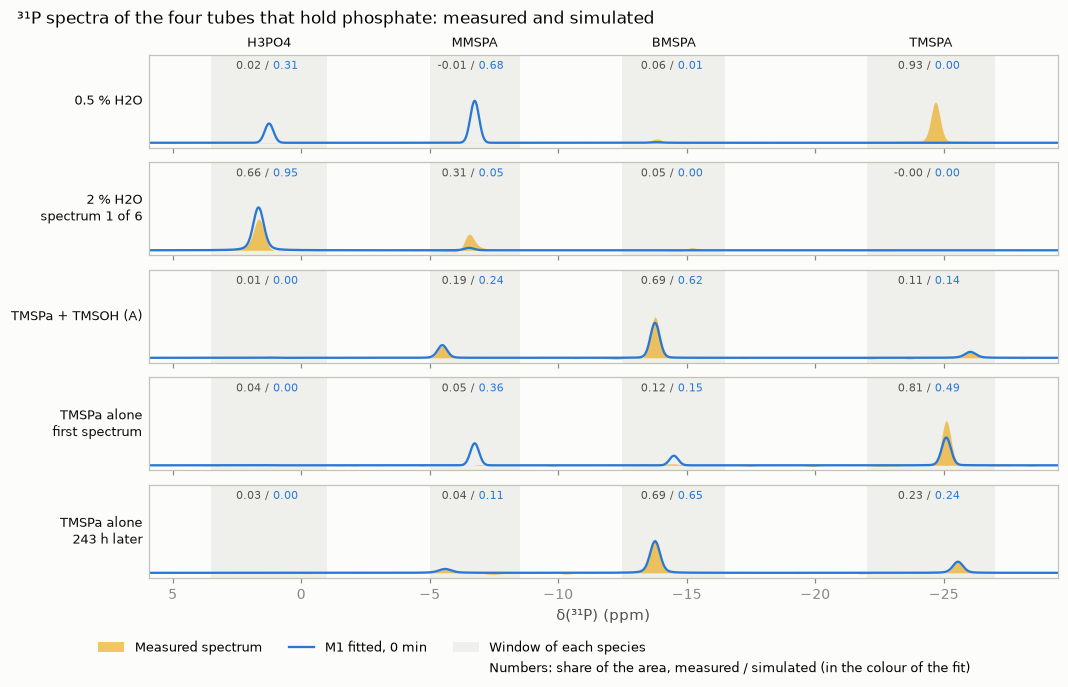

In [4]:
spectra = load_measured_spectra(observables)        # the raw spectra behind the shares (needs LAB_NMR_DIR)
phosphate_rows = [('0.5 % H2O', 0, ''), ('2 % H2O', 0, 'spectrum 1 of 6'), ('TMSPa + TMSOH (A)', 0, ''),
                  ('TMSPa alone', 0, 'first spectrum'), ('TMSPa alone', 1, '243 h later')]
fit_plots.plot_spectra_comparison(spectra, shares['0 min'], nucleus='31P', fit_label=f'{MAIN} fitted, 0 min', rows=phosphate_rows,
                                  title='³¹P spectra of the four tubes that hold phosphate: measured and simulated');

Largest difference of a simulated share between the three readings: 0.011


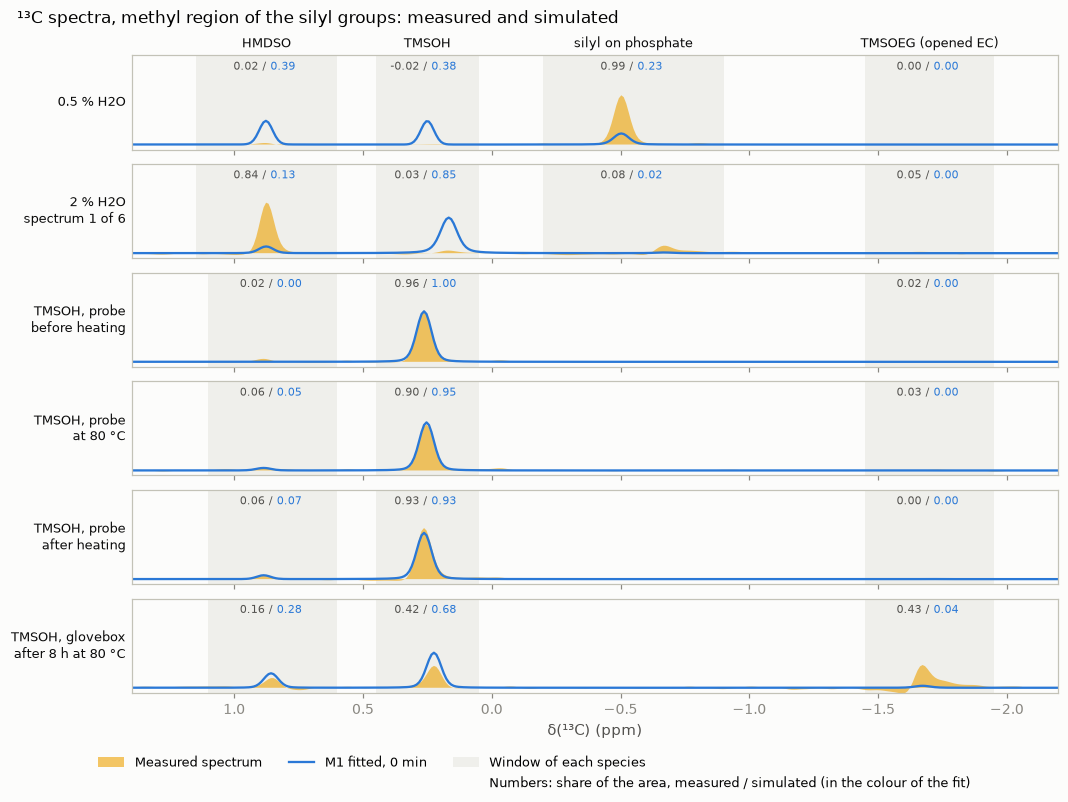

In [5]:
fit_plots.plot_spectra_comparison(spectra, shares['0 min'], nucleus='13C', fit_label=f'{MAIN} fitted, 0 min', title='¹³C spectra, methyl region of the silyl groups: measured and simulated',
                                  rows=[('0.5 % H2O', 0, ''), ('2 % H2O', 0, 'spectrum 1 of 6'), ('TMSOH, probe', 0, 'before heating'),
                                        ('TMSOH, probe', 1, 'at 80 °C'), ('TMSOH, probe', 2, 'after heating'), ('TMSOH, glovebox', 0, 'after 8 h at 80 °C')]);
# The other two readings: how far their simulated shares are from one another, at most
spread = pd.concat({scenario: shares[scenario].set_index(['sample', 'nucleus', 'spectrum', 'window'])['predicted'] for scenario in READINGS}, axis=1)
print(f'Largest difference of a simulated share between the three readings: {(spread.max(axis=1) - spread.min(axis=1)).max():.3f}')

Negative area (TMSOEG, glovebox): the file stores a time signal; turning it into a spectrum needs a phase angle, and one angle is used for the whole region.


That angle is set by the largest lines and is slightly off for TMSOEG, so its line comes out tilted and dips below zero on one side. It is a processing artefact, not signal.


In [6]:
gap = shares['0 min'].assign(miss=lambda d: (d['predicted'] - d['measured']) / d['sigma'])
(gap.loc[gap['miss'].abs().nlargest(5).index, ['sample', 'nucleus', 'spectrum', 'window', 'measured', 'predicted', 'sigma', 'miss']]
 .sort_values(['sample', 'nucleus', 'spectrum'])
 .rename(columns={'sample': 'tube', 'spectrum': 'spectrum (0 = first)', 'window': 'line', 'predicted': 'simulated', 'sigma': 'error'})
 .style.hide(axis='index').format(precision=2))

tube,nucleus,spectrum (0 = first),line,measured,simulated,error,miss
0.5 % H2O,31P,0,MMSPA,-0.01,0.68,0.02,41.73
0.5 % H2O,31P,0,TMSPA,0.93,0.00,0.05,-18.46
2 % H2O,13C,1,TMSOH,0.08,0.95,0.05,19.17
2 % H2O,13C,2,TMSOH,0.05,0.95,0.05,17.42
2 % H2O,13C,3,TMSOH,0.01,0.95,0.06,16.33


The five fitted shares where the model is furthest from the measurement (0 min).

- Error: uncertainty of the measured share (noise, baseline and a minimum floor).
- Miss = (simulated − measured) / error. The fit rule allows 3.

Two are in `0.5 % H2O`: MMSPA, 0.68 simulated where none is measured (42 errors), and TMSPA, none simulated where 0.93 is measured (18 errors). The other three are the TMSOH line of `2 % H2O` in its second to fourth spectra: about 0.95 simulated, 0.01 to 0.08 measured (16 to 19 errors).

**Conclusions**

M1 runs every reaction with water within a second (§2.2) and stops each one where the computed energies put it.

- **0.5 % H2O**: simulated, no TMSPA left and the phosphate as MMSPA (0.68) and H₃PO₄ (0.31). Measured, TMSPA almost intact (0.93). This is the worst miss of the fit.

- **2 % H2O**: too much H₃PO₄ (0.95 simulated, 0.66 measured) and too little MMSPA (0.05 against 0.31). On ¹³C the silyl groups stay as TMSOH (0.85 simulated, 0.03 measured in the first spectrum) where the tube shows HMDSO (0.13 against 0.84).

- **TMSPa + TMSOH (A)**: described. BMSPA 0.62 against 0.69; every miss within about 1 error.

- **TMSPa alone**: the first spectrum is missed, the second is not. First: TMSPA 0.49 against 0.81, MMSPA 0.36 against 0.05. 243 h later: TMSPA 0.24 against 0.23, BMSPA 0.65 against 0.69.

- **TMSOH, probe**: described; TMSOH barely changes, even at 80 °C.

- **TMSOH, glovebox**: too little of the solvent opened: TMSOEG 0.04 simulated against 0.43 measured (5 errors), and TMSOH left over (0.68 against 0.42).

- **So M1 fails in the two tubes with added water**, and by less in the first spectrum of `TMSPa alone` and in `TMSOH, glovebox`. The tubes without water and the late spectrum of `TMSPa alone` are described.

---

### 2.2 Concentrations in time

What does M1 make of each tube between mixing and its spectra?

- **The clock:** `t = 0` is the addition of TMSPA (of TMSOH, in the TMSOH tubes). The reading puts the first acquisition 0, 5 or 10 min later; the spectra follow at their recorded times after it.
- **The two tubes with added water** start 36 h earlier, with the solvent and the water alone (drawn from the bench protocol, not simulated by the fit).
- **`2 % H2O`** is heated for 8 h at each step of its ramp (30 … 80 °C), as the paper says. The run sets this for every fit (`sample_overrides` in `fit_config.json`), so the evaluations of the setup cell already carry it. The cell below lists the heating they use.
- **`TMSOH, glovebox`** was kept at 80 °C for the first 8 h, which was recorded.
- Each vertical line is an NMR spectrum (the ³¹P and ¹³C scans of one round count as one); the curves are the model, the points the measured amounts. Amounts below 1 µM are drawn as 0, and every axis starts at 0.
- The three readings follow one another (2.2.1 to 2.2.3).

TEMPNOTE

In [7]:
# The heating of `2 % H2O` in the evaluations: 8 h at each step of the ramp, from fit_config.json (sample_overrides)
heated = next(sample for sample in views['0 min']['samples'] if sample['name'] == '2 % H2O')['heated']
pd.DataFrame([{'starts (h after the first spectrum)': start / 3600.0, 'at (°C)': T_K - ZERO_CELSIUS_K, 'lasts (h)': duration / 3600.0}
              for start, T_K, duration in heated]).round(1).rename_axis('2 % H2O: heating step')

,starts (h after the first spectrum),at (°C),lasts (h)
2 % H2O: heating step,,,
0,13.3,30.0,8.0
1,21.3,40.0,8.0
2,63.0,50.0,8.0
3,87.0,60.0,8.0
4,109.9,70.0,8.0
5,136.0,80.0,8.0


#### 2.2.1. M1, 0 min

when reducing age, we do reactions faster? i see same curves but less time, also we told that a lot of tmsoh was generated, but in the plot i see little, should we plot more time?

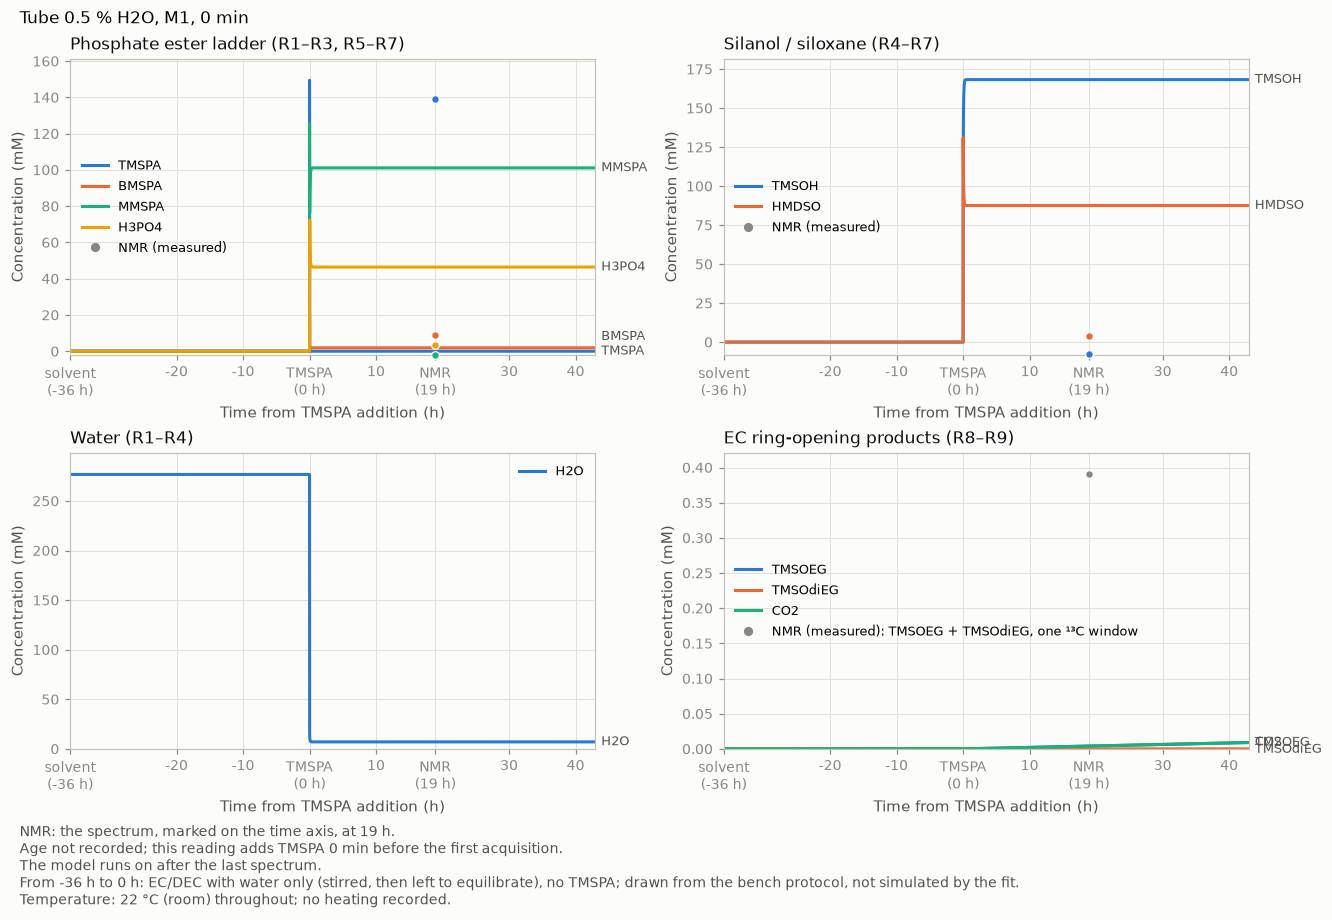

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
18.9,³¹P,TMSPA,139.0,0.0,-139.0,-18.5
18.9,³¹P,BMSPA,9.0,1.9,-7.1,-3.5
18.9,³¹P,MMSPA,-1.9,101.1,+103.0,+41.7
18.9,³¹P,H3PO4,3.4,46.4,+43.1,+9.8
18.9,¹³C,TMSOH,-7.6,168.3,+175.9,+12.7
18.9,¹³C,HMDSO,7.6,175.1,+167.5,+11.3
18.9,¹³C,TMSOEG (opened EC),0.4,0.0,-0.4,-0.0
18.9,¹³C,silyl on phosphate,445.9,104.9,-341.1,-5.1


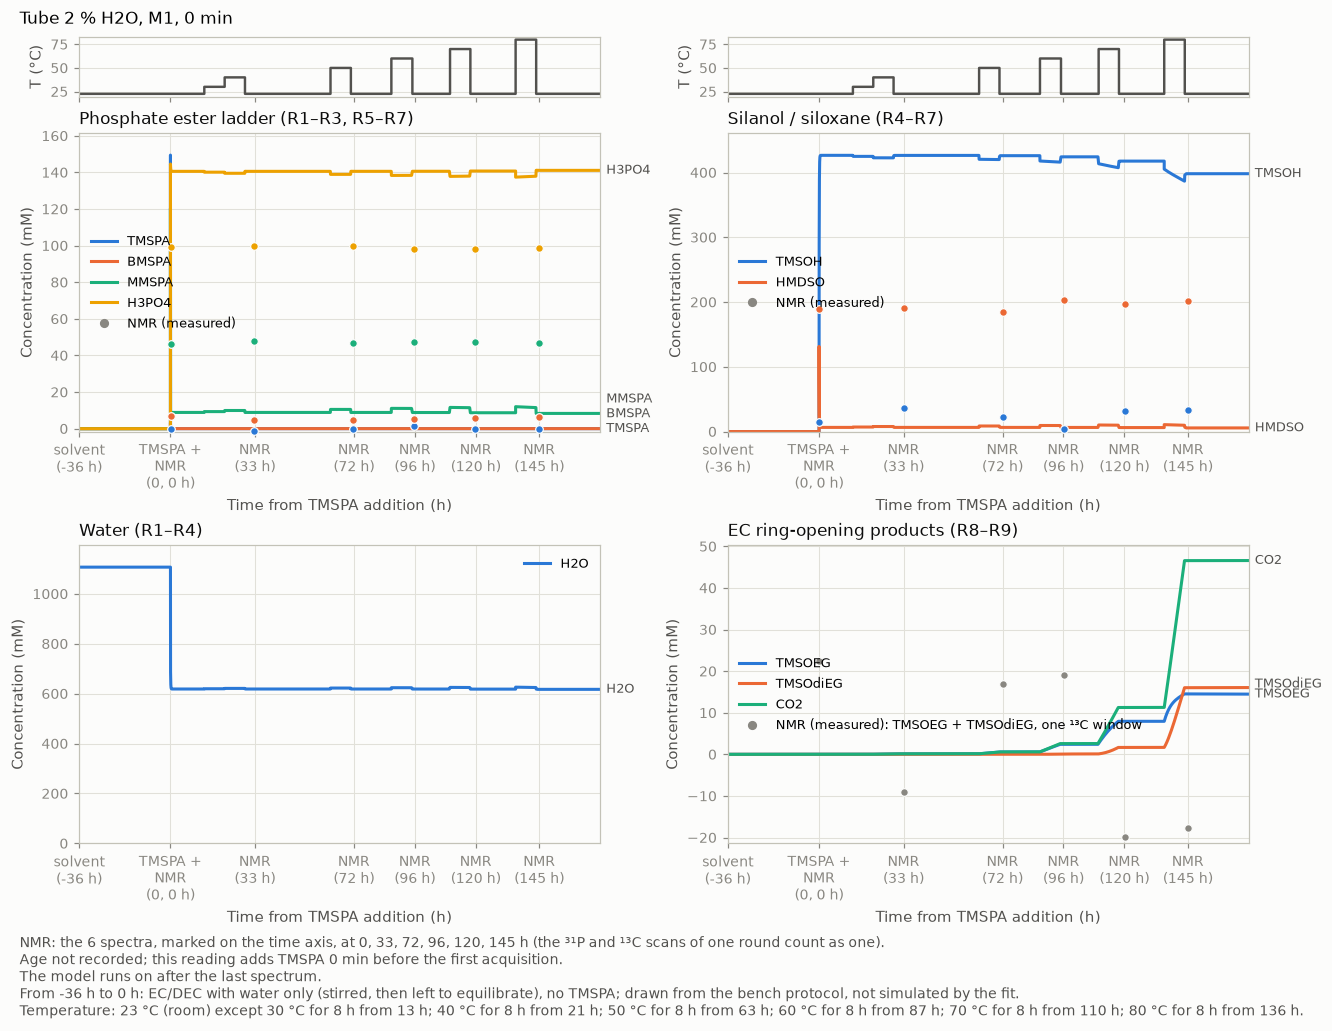

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.1,³¹P,TMSPA,-0.2,0.0,+0.2,+0.0
0.1,³¹P,BMSPA,7.1,0.0,-7.1,-2.6
0.1,³¹P,MMSPA,46.5,7.2,-39.3,-11.3
0.1,³¹P,H3PO4,99.3,142.2,+42.9,+7.5
0.1,¹³C,TMSOH,15.2,383.3,+368.0,+15.1
0.1,¹³C,HMDSO,378.3,57.0,-321.3,-4.3
0.1,¹³C,TMSOEG (opened EC),22.5,0.0,-22.5,-0.8
0.1,¹³C,silyl on phosphate,36.8,8.0,-28.8,-1.0
33.1,³¹P,TMSPA,-1.5,0.0,+1.5,+0.6
33.1,³¹P,BMSPA,5.0,0.0,-5.0,-2.6


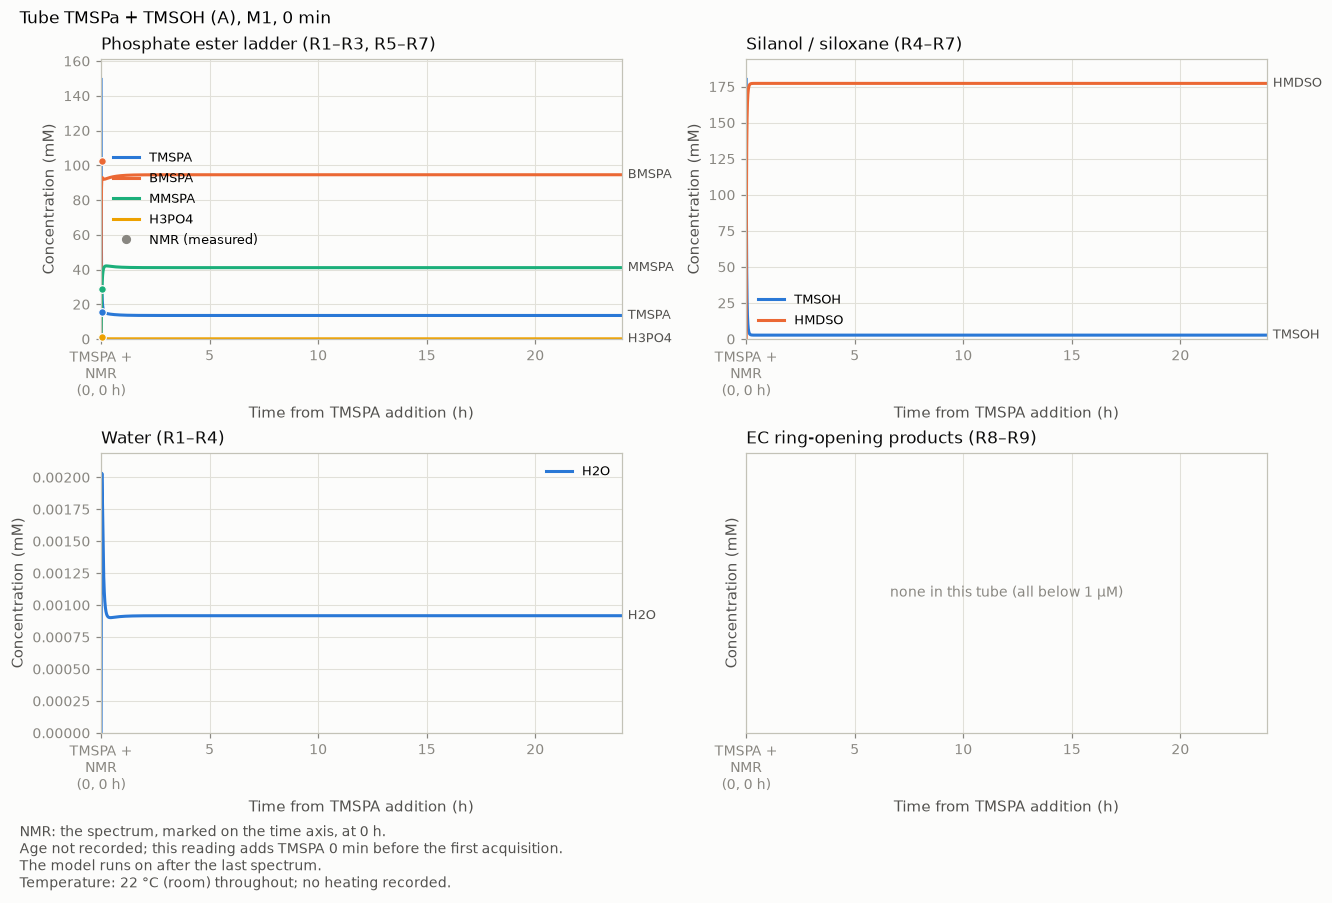

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.1,³¹P,TMSPA,15.7,20.9,+5.1,+0.8
0.1,³¹P,BMSPA,102.7,92.9,-9.8,-1.0
0.1,³¹P,MMSPA,29.0,35.2,+6.2,+1.0
0.1,³¹P,H3PO4,1.5,0.5,-1.0,-0.1


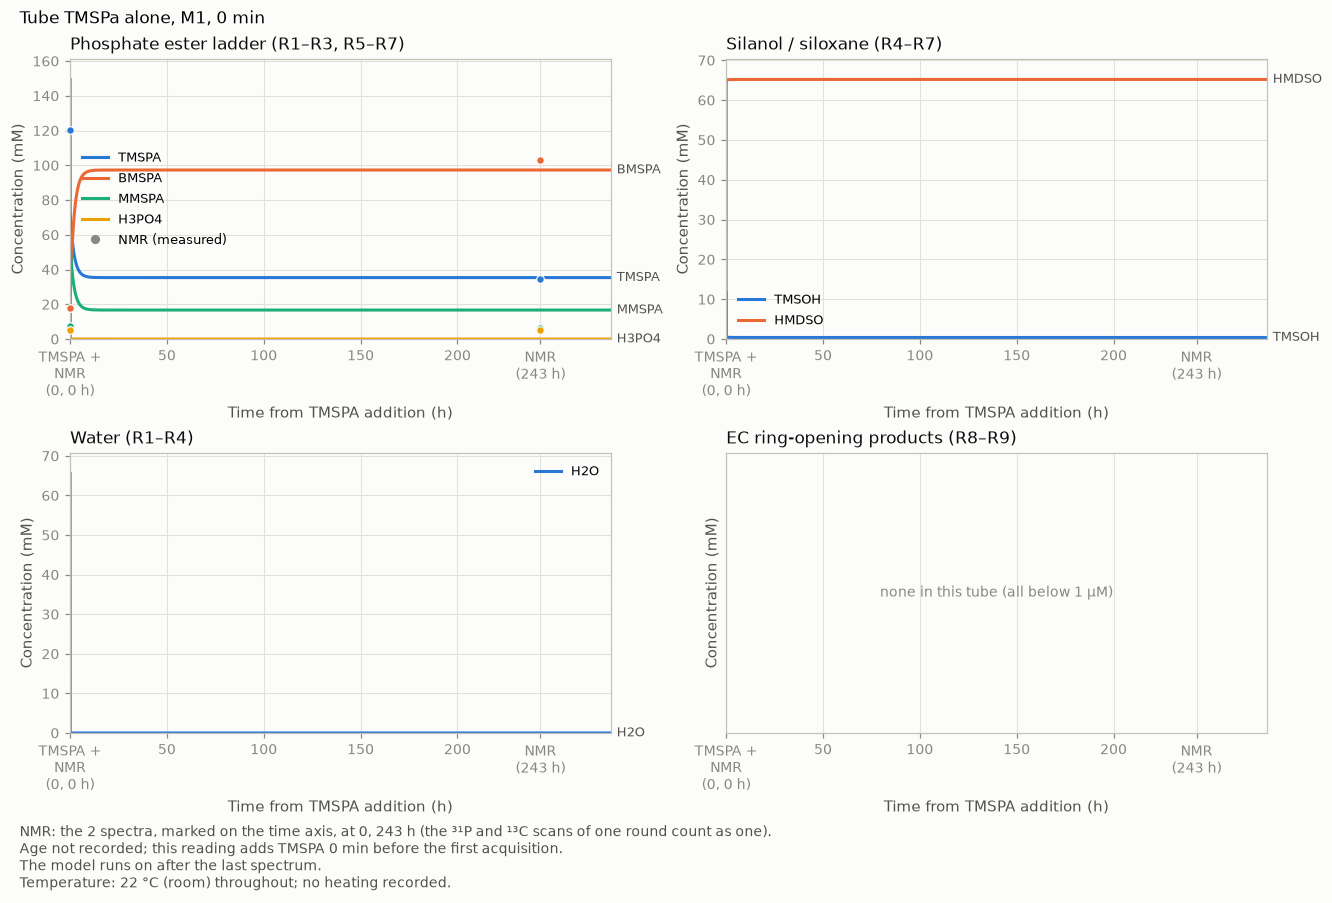

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.1,³¹P,TMSPA,120.5,73.1,-47.4,-4.9
0.1,³¹P,BMSPA,17.7,23.0,+5.3,+0.7
0.1,³¹P,MMSPA,7.4,53.1,+45.7,+6.8
0.1,³¹P,H3PO4,5.4,0.3,-5.1,-0.9
242.9,³¹P,TMSPA,34.6,35.4,+0.8,+0.1
242.9,³¹P,BMSPA,102.8,97.3,-5.5,-0.6
242.9,³¹P,MMSPA,6.2,16.7,+10.5,+1.5
242.9,³¹P,H3PO4,5.1,0.0,-5.1,-0.9


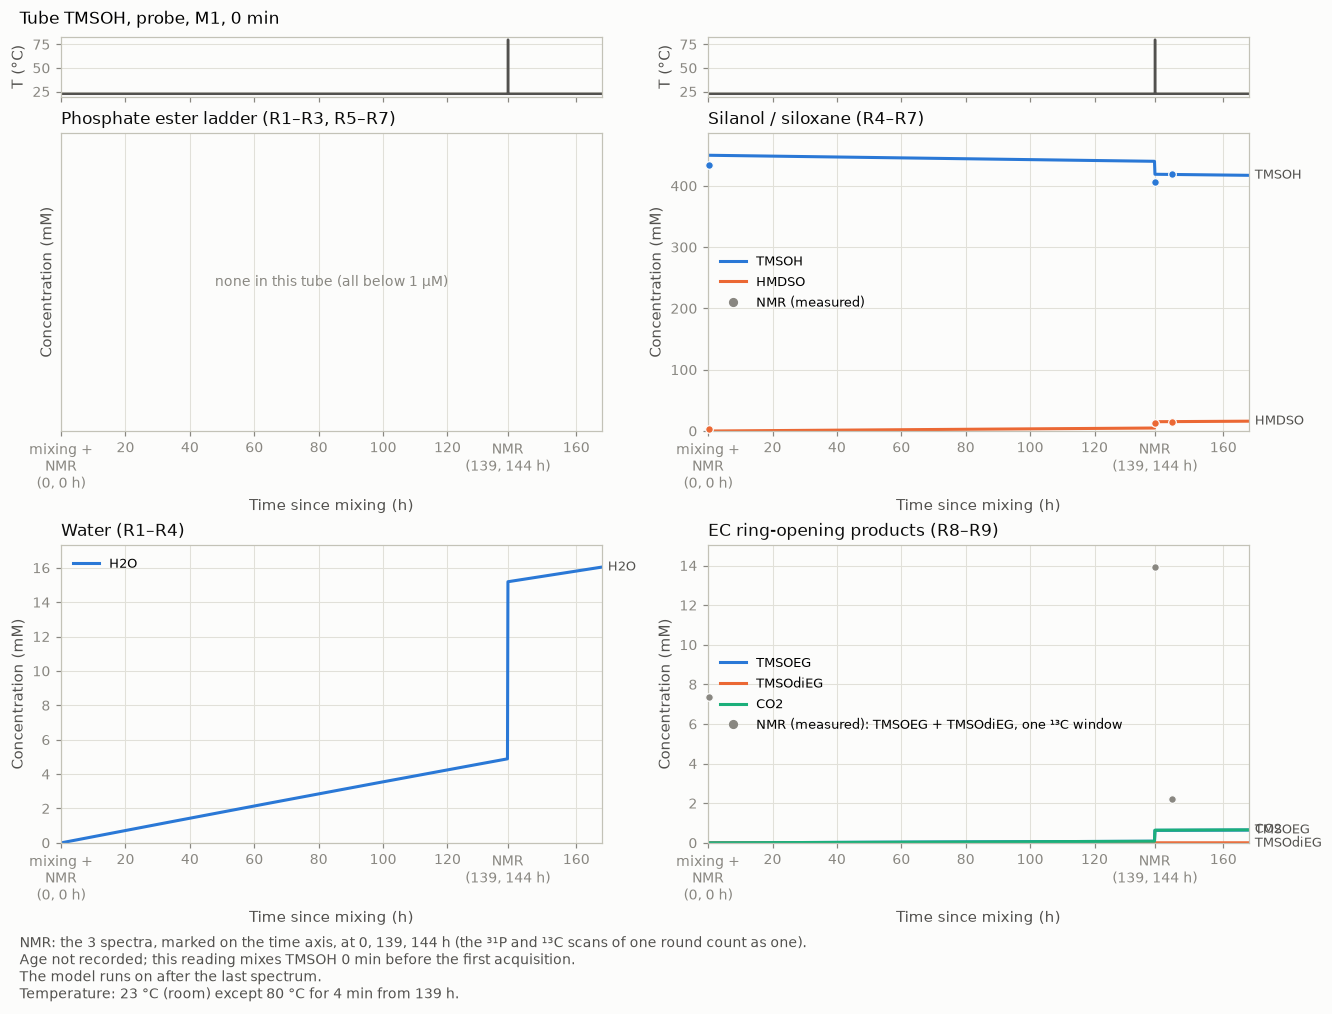

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.2,¹³C,TMSOH,433.8,450.0,+16.2,+0.2
0.2,¹³C,HMDSO,7.7,0.0,-7.6,-0.4
0.2,¹³C,TMSOEG (opened EC),7.4,0.0,-7.4,-0.5
138.7,¹³C,TMSOH,405.6,427.1,+21.4,+0.3
138.7,¹³C,HMDSO,25.2,22.5,-2.7,-0.2
138.7,¹³C,TMSOEG (opened EC),13.9,0.4,-13.5,-0.8
144.1,¹³C,TMSOH,419.1,418.7,-0.5,-0.0
144.1,¹³C,HMDSO,28.6,30.7,+2.1,+0.1
144.1,¹³C,TMSOEG (opened EC),2.2,0.6,-1.6,-0.1


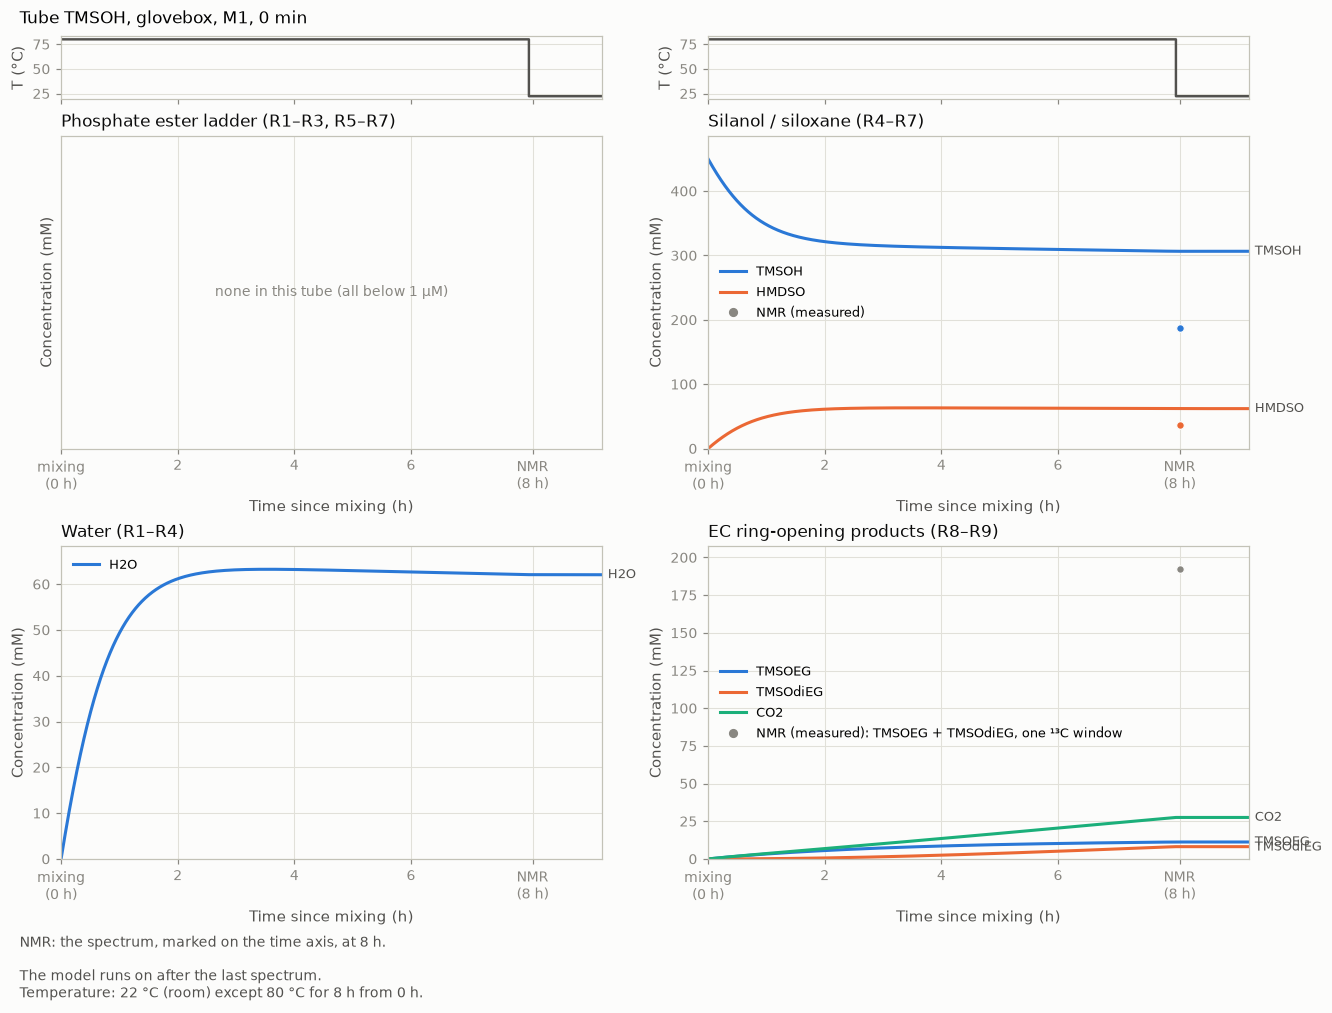

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
8.1,¹³C,TMSOH,188.0,306.5,+118.5,+3.9
8.1,¹³C,HMDSO,72.3,124.2,+51.9,+1.8
8.1,¹³C,TMSOEG (opened EC),192.2,19.4,-172.8,-5.0


In [8]:
import matplotlib.pyplot as plt

reading = '0 min'
trajectories = simulate_fit_trajectories(views[reading], until_h=1500.0, t_first_h=1e-4, n_points=4000)
spectrum_times = shares[reading].groupby('sample')['t_h'].unique()
before = {tube: f'Age not recorded; this reading adds TMSPA {reading} before the first acquisition.' for tube in PHOSPHATE_TUBES}
before['TMSOH, probe'] = f'Age not recorded; this reading mixes TMSOH {reading} before the first acquisition.'
for tube in PHOSPHATE_TUBES + ['TMSOH, probe', 'TMSOH, glovebox']:
    fit_plots.plot_tube_concentrations(trajectories, tube, spectrum_times[tube], model=f'{MAIN}, {reading}', before=before.get(tube),
                                       solvent_stage=tube in ('0.5 % H2O', '2 % H2O'), measured=shares[reading])
    plt.show()                                       # the figure first, then its table
    fit_plots.show_tube_comparison(shares[reading], tube)

#### 2.2.2. M1, 5 min

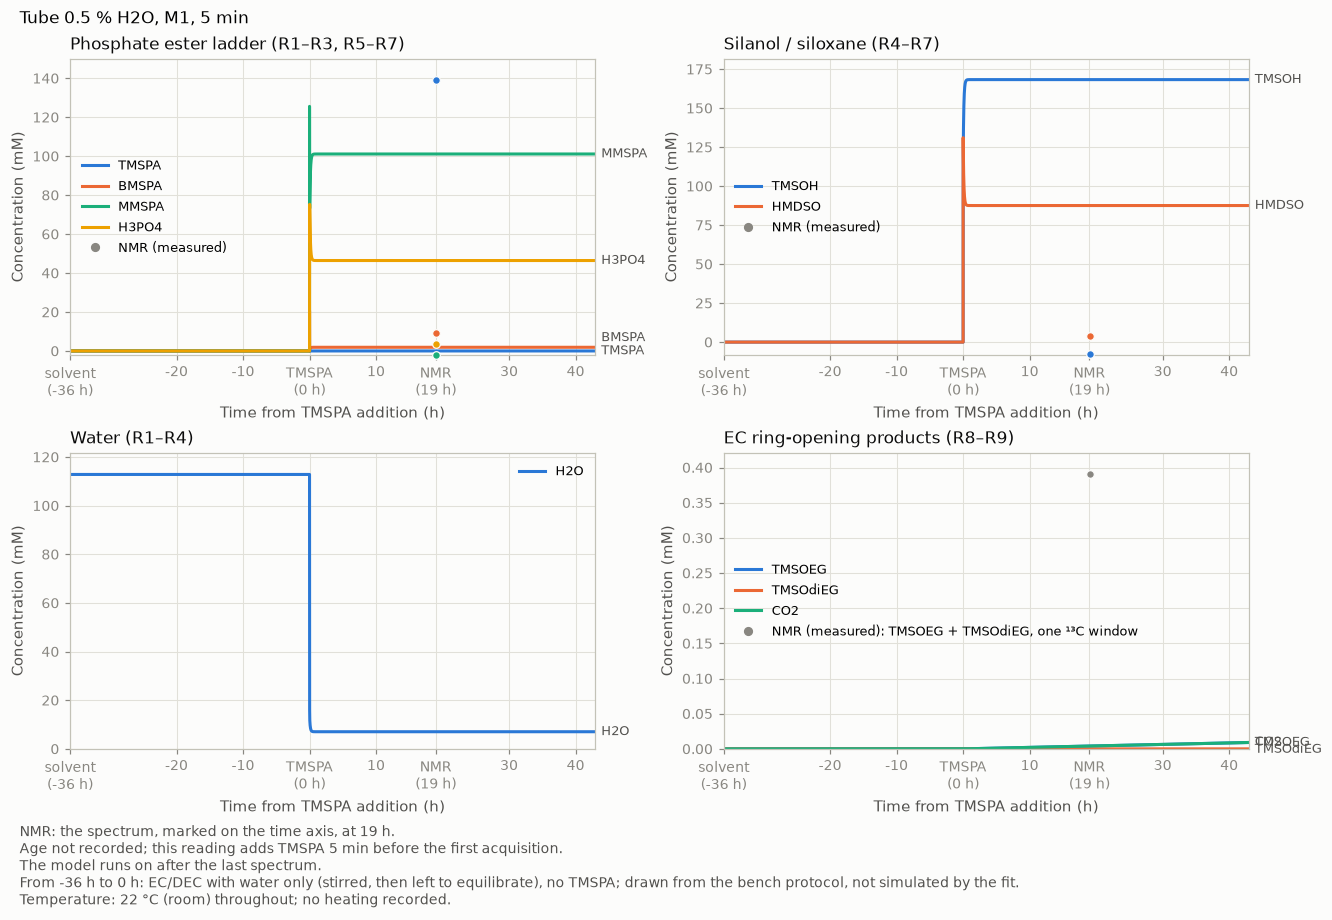

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
18.9,³¹P,TMSPA,139.0,0.0,-139.0,-18.5
18.9,³¹P,BMSPA,9.0,1.9,-7.1,-3.5
18.9,³¹P,MMSPA,-1.9,101.1,+103.0,+41.7
18.9,³¹P,H3PO4,3.4,46.4,+43.1,+9.8
19.0,¹³C,TMSOH,-7.6,168.3,+175.9,+12.7
19.0,¹³C,HMDSO,7.6,175.1,+167.5,+11.3
19.0,¹³C,TMSOEG (opened EC),0.4,0.0,-0.4,-0.0
19.0,¹³C,silyl on phosphate,445.9,104.9,-341.1,-5.1


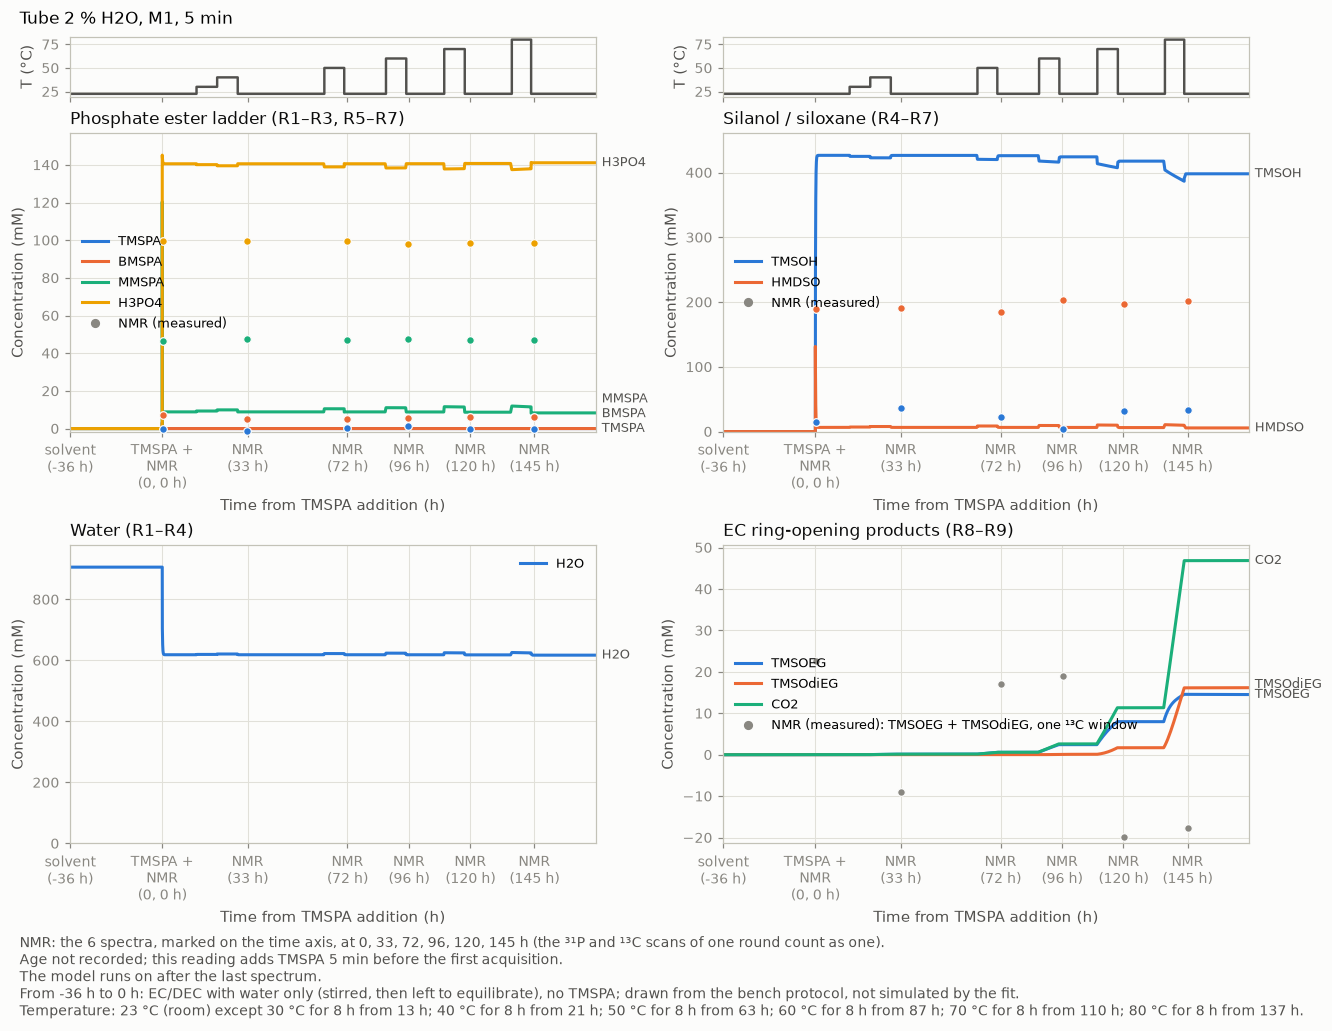

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.2,³¹P,TMSPA,-0.2,0.0,+0.2,+0.0
0.2,³¹P,BMSPA,7.1,0.0,-7.1,-2.6
0.2,³¹P,MMSPA,46.5,7.3,-39.1,-11.2
0.2,³¹P,H3PO4,99.3,142.1,+42.8,+7.5
0.2,¹³C,TMSOH,15.2,380.7,+365.5,+15.0
0.2,¹³C,HMDSO,378.3,59.7,-318.6,-4.3
0.2,¹³C,TMSOEG (opened EC),22.5,0.0,-22.5,-0.8
0.2,¹³C,silyl on phosphate,36.8,7.9,-29.0,-1.0
33.2,³¹P,TMSPA,-1.5,0.0,+1.5,+0.6
33.2,³¹P,BMSPA,5.0,0.0,-5.0,-2.6


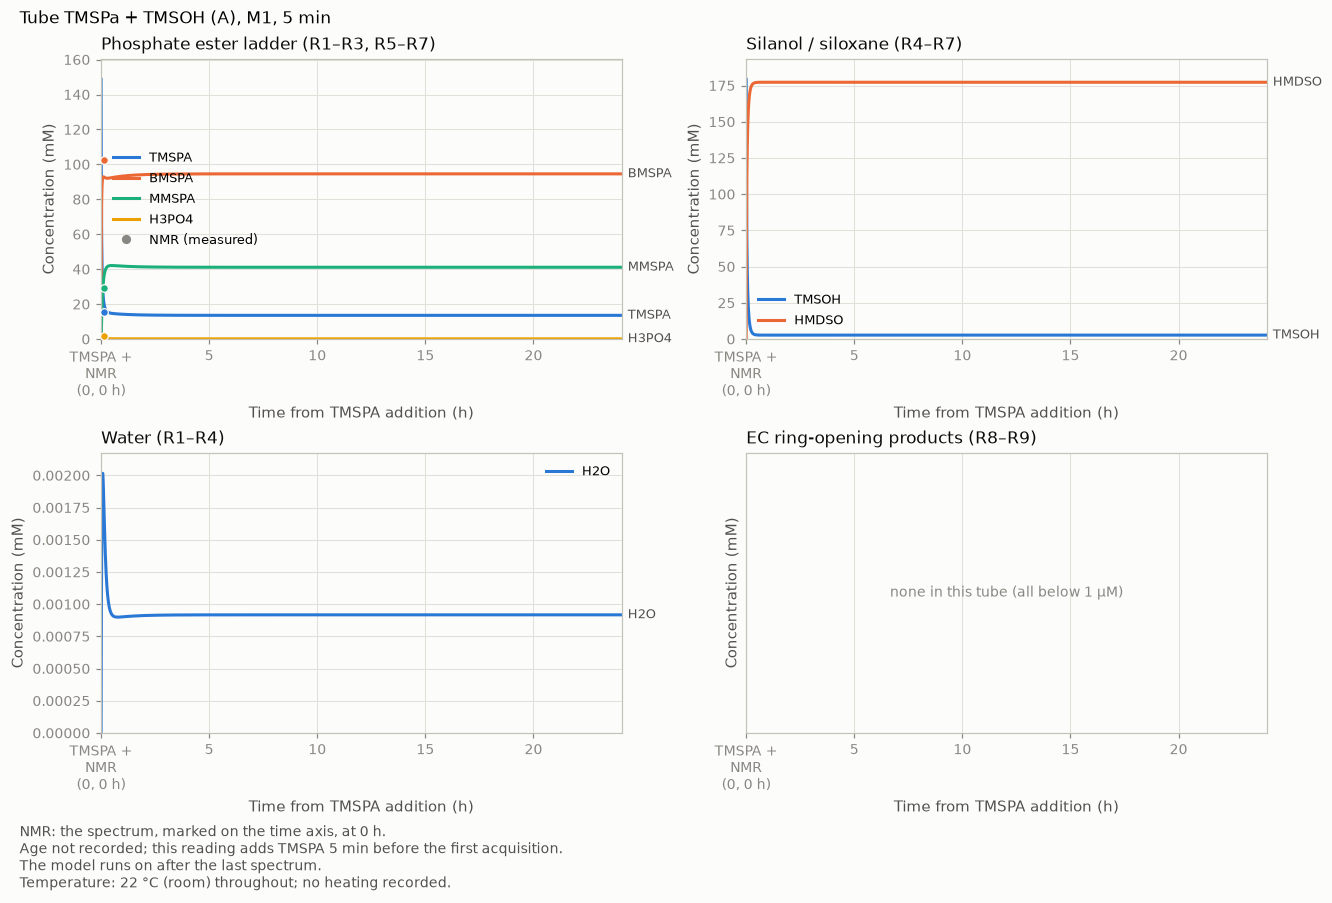

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.1,³¹P,TMSPA,15.7,19.5,+3.8,+0.6
0.1,³¹P,BMSPA,102.7,92.7,-10.0,-1.0
0.1,³¹P,MMSPA,29.0,36.8,+7.8,+1.2
0.1,³¹P,H3PO4,1.5,0.4,-1.0,-0.1


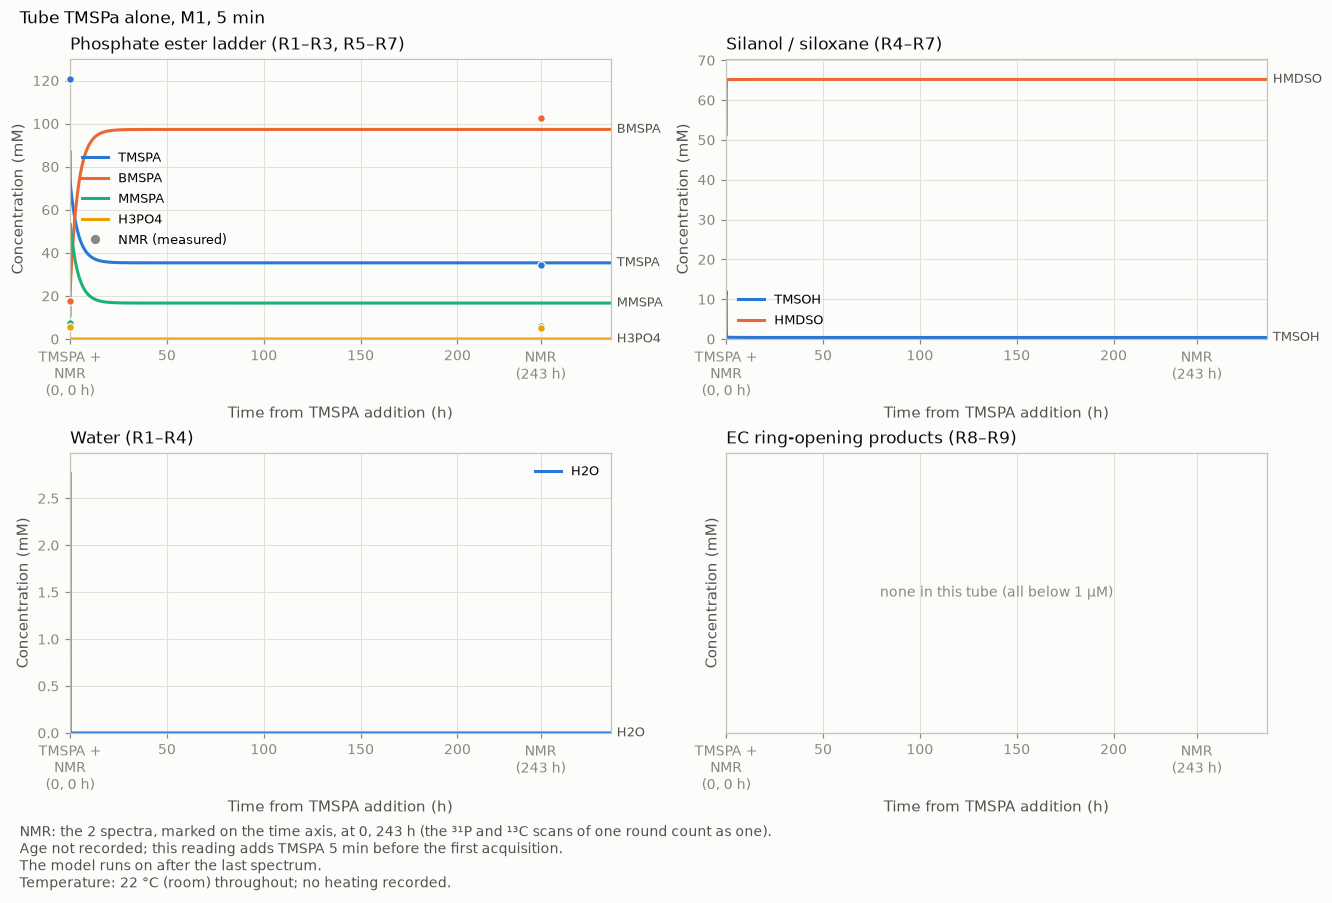

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.1,³¹P,TMSPA,120.5,72.4,-48.1,-4.9
0.1,³¹P,BMSPA,17.7,23.9,+6.2,+0.8
0.1,³¹P,MMSPA,7.4,52.9,+45.5,+6.8
0.1,³¹P,H3PO4,5.4,0.2,-5.2,-0.9
243.0,³¹P,TMSPA,34.6,35.4,+0.8,+0.1
243.0,³¹P,BMSPA,102.8,97.3,-5.5,-0.6
243.0,³¹P,MMSPA,6.2,16.7,+10.5,+1.5
243.0,³¹P,H3PO4,5.1,0.0,-5.1,-0.9


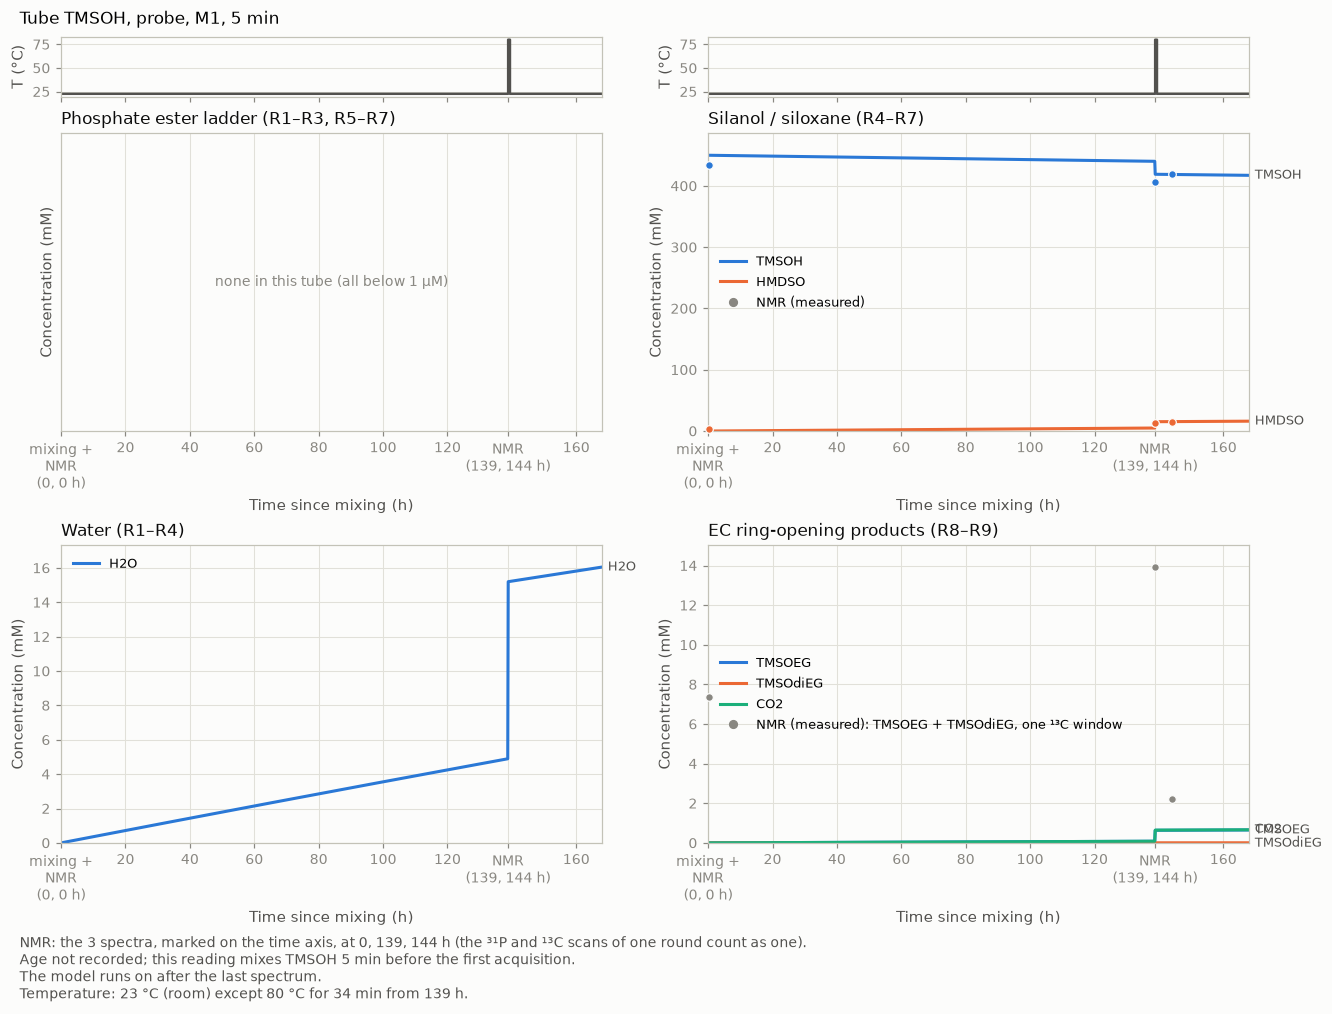

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.3,¹³C,TMSOH,433.8,450.0,+16.2,+0.2
0.3,¹³C,HMDSO,7.7,0.0,-7.6,-0.4
0.3,¹³C,TMSOEG (opened EC),7.4,0.0,-7.4,-0.5
138.8,¹³C,TMSOH,405.6,427.1,+21.4,+0.3
138.8,¹³C,HMDSO,25.2,22.5,-2.7,-0.2
138.8,¹³C,TMSOEG (opened EC),13.9,0.4,-13.5,-0.8
144.1,¹³C,TMSOH,419.1,418.6,-0.5,-0.0
144.1,¹³C,HMDSO,28.6,30.7,+2.1,+0.1
144.1,¹³C,TMSOEG (opened EC),2.2,0.6,-1.6,-0.1


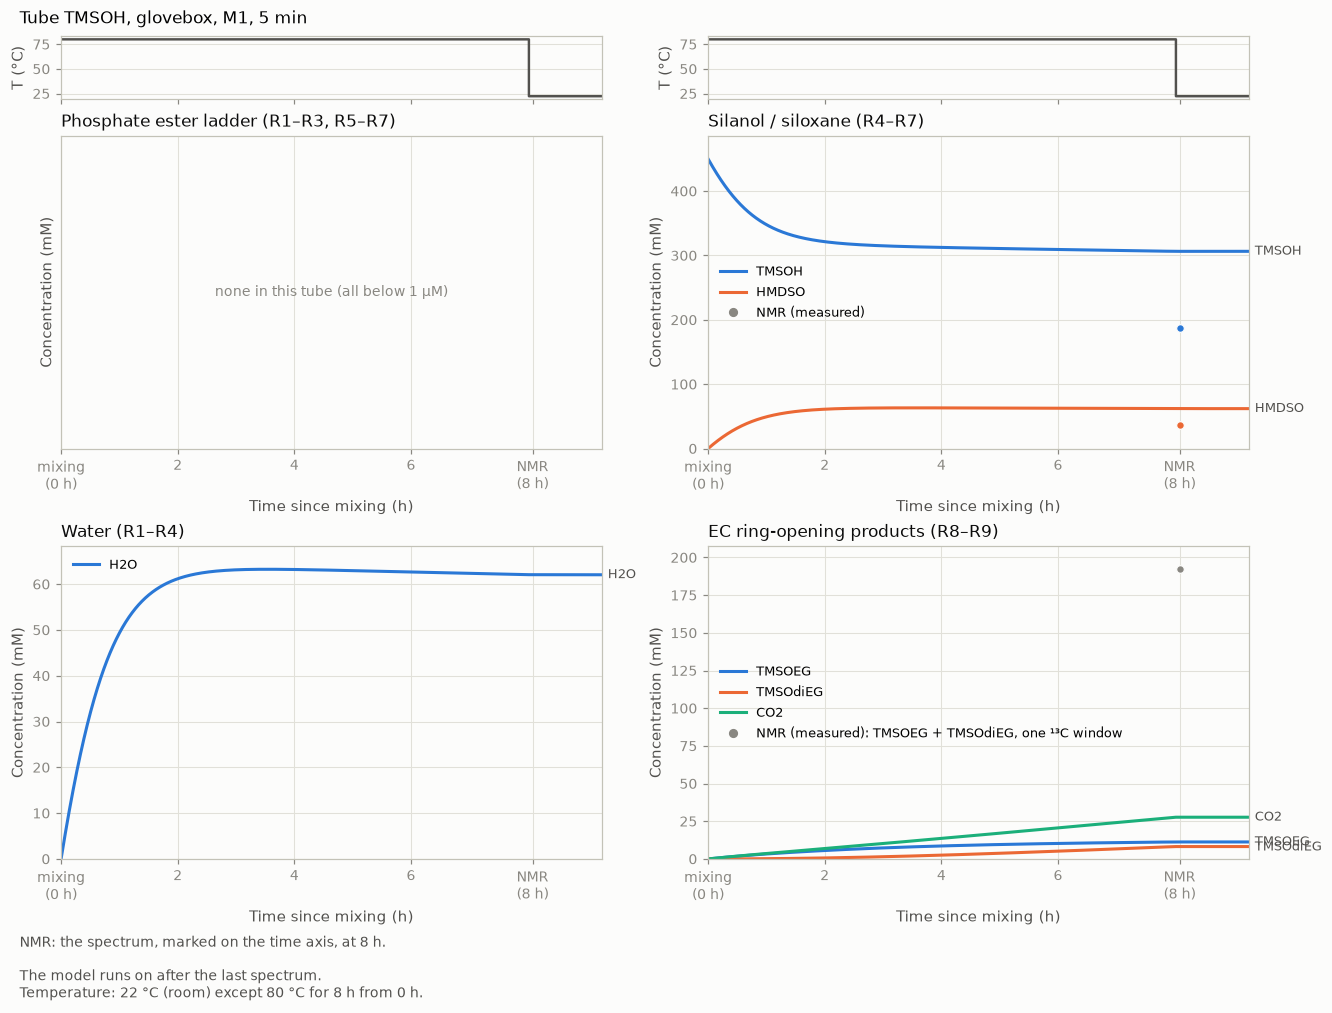

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
8.1,¹³C,TMSOH,188.0,306.4,+118.4,+3.9
8.1,¹³C,HMDSO,72.3,124.1,+51.9,+1.8
8.1,¹³C,TMSOEG (opened EC),192.2,19.5,-172.7,-5.0


In [9]:
import matplotlib.pyplot as plt

reading = '5 min'
trajectories = simulate_fit_trajectories(views[reading], until_h=1500.0, t_first_h=1e-4, n_points=4000)
spectrum_times = shares[reading].groupby('sample')['t_h'].unique()
before = {tube: f'Age not recorded; this reading adds TMSPA {reading} before the first acquisition.' for tube in PHOSPHATE_TUBES}
before['TMSOH, probe'] = f'Age not recorded; this reading mixes TMSOH {reading} before the first acquisition.'
for tube in PHOSPHATE_TUBES + ['TMSOH, probe', 'TMSOH, glovebox']:
    fit_plots.plot_tube_concentrations(trajectories, tube, spectrum_times[tube], model=f'{MAIN}, {reading}', before=before.get(tube),
                                       solvent_stage=tube in ('0.5 % H2O', '2 % H2O'), measured=shares[reading])
    plt.show()                                       # the figure first, then its table
    fit_plots.show_tube_comparison(shares[reading], tube)

#### 2.2.3. M1, 10 min

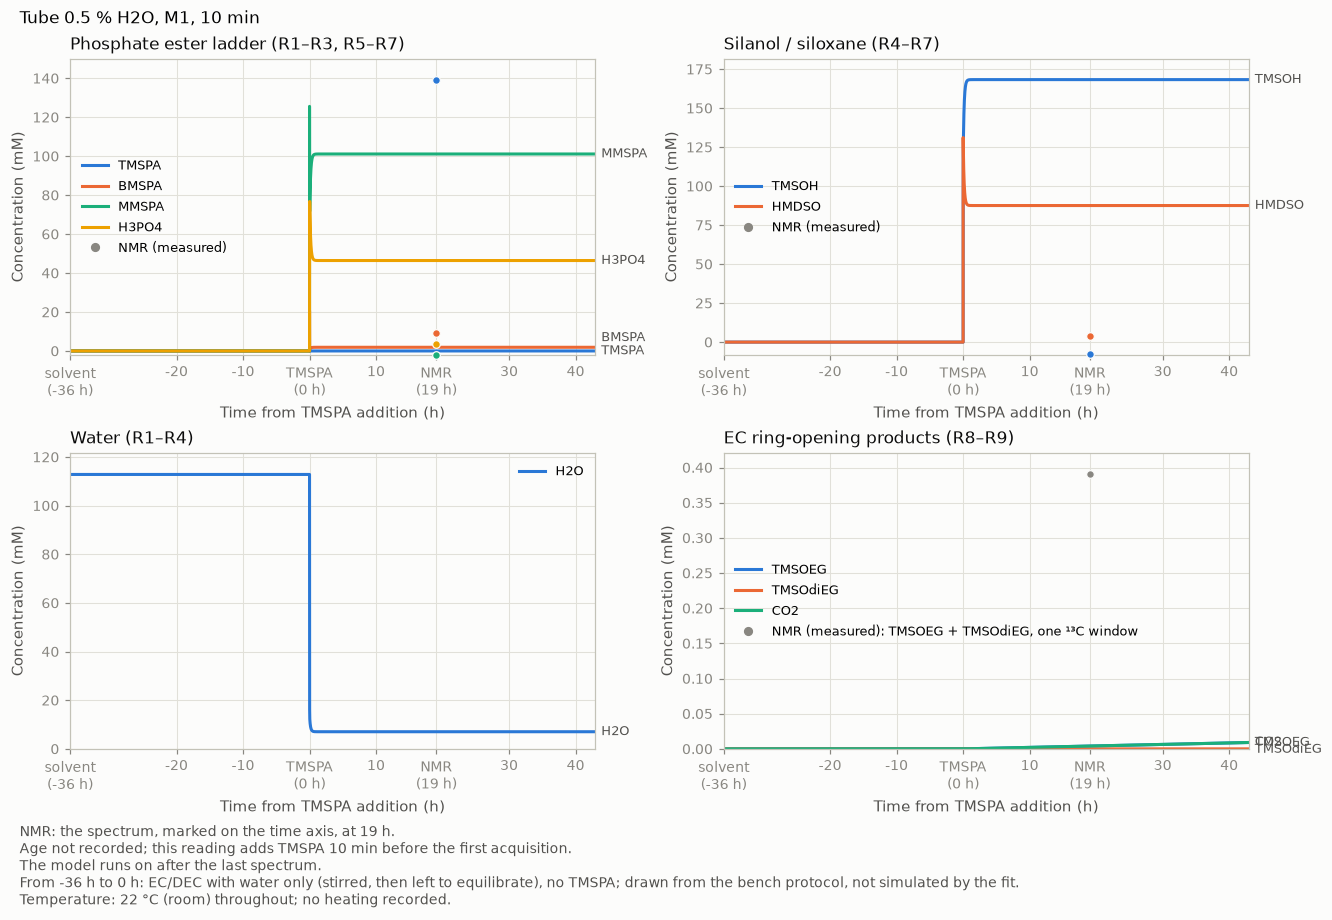

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
19.0,³¹P,TMSPA,139.0,0.0,-139.0,-18.5
19.0,³¹P,BMSPA,9.0,1.9,-7.1,-3.5
19.0,³¹P,MMSPA,-1.9,101.1,+103.0,+41.7
19.0,³¹P,H3PO4,3.4,46.4,+43.1,+9.8
19.1,¹³C,TMSOH,-7.6,168.3,+175.9,+12.7
19.1,¹³C,HMDSO,7.6,175.1,+167.5,+11.3
19.1,¹³C,TMSOEG (opened EC),0.4,0.0,-0.4,-0.0
19.1,¹³C,silyl on phosphate,445.9,104.9,-341.1,-5.1


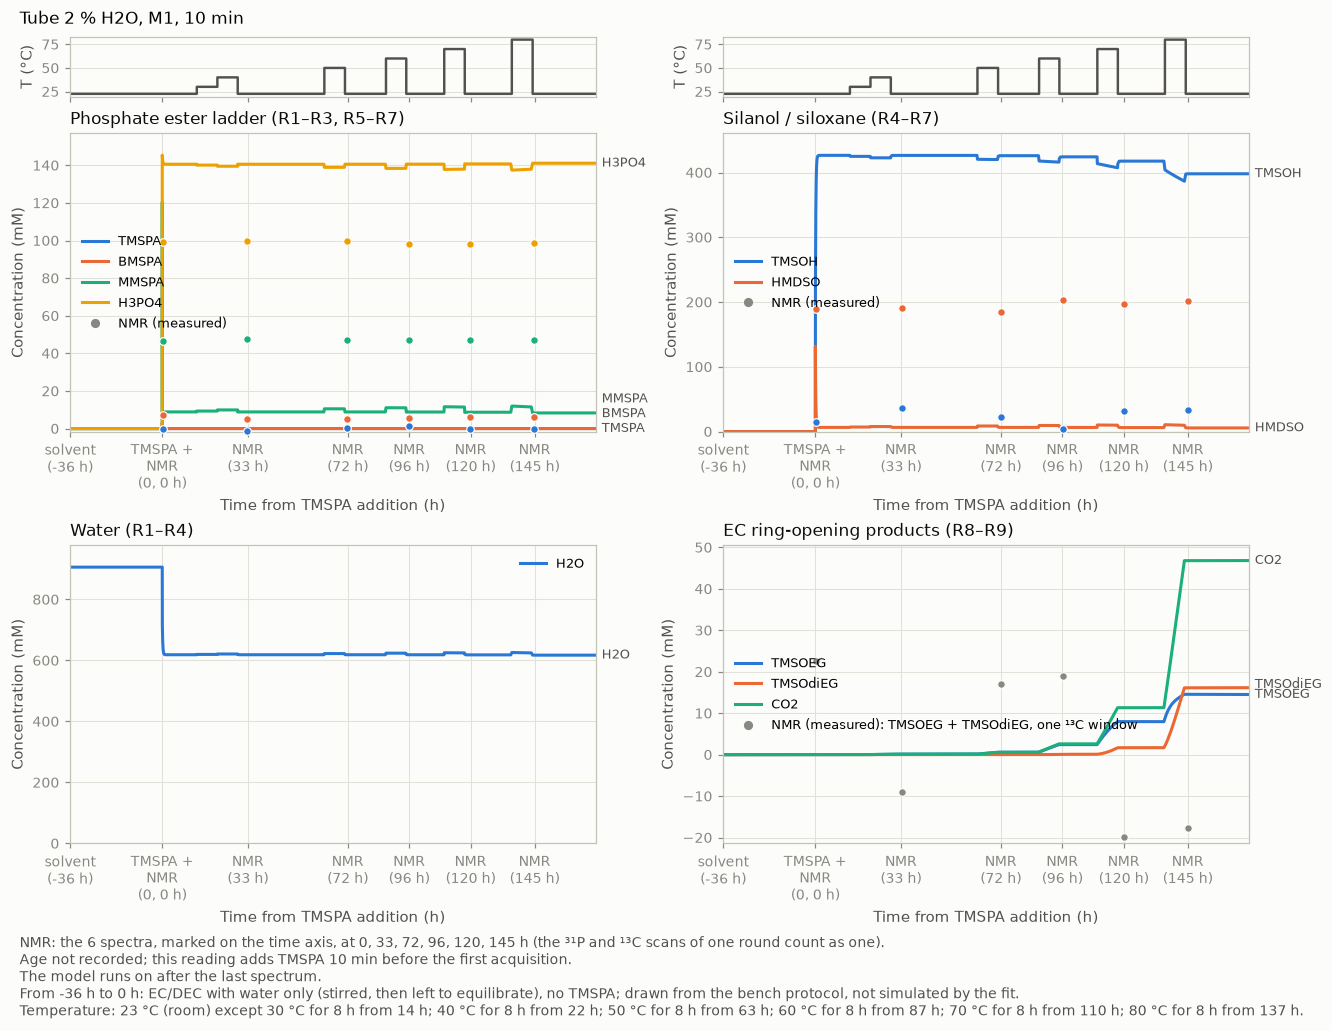

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.2,³¹P,TMSPA,-0.2,0.0,+0.2,+0.0
0.2,³¹P,BMSPA,7.1,0.0,-7.1,-2.6
0.2,³¹P,MMSPA,46.5,7.5,-39.0,-11.2
0.2,³¹P,H3PO4,99.3,142.0,+42.6,+7.5
0.3,¹³C,TMSOH,15.2,380.8,+365.5,+15.0
0.3,¹³C,HMDSO,378.3,59.7,-318.6,-4.3
0.3,¹³C,TMSOEG (opened EC),22.5,0.0,-22.5,-0.8
0.3,¹³C,silyl on phosphate,36.8,7.8,-29.0,-1.0
33.2,³¹P,TMSPA,-1.5,0.0,+1.5,+0.6
33.2,³¹P,BMSPA,5.0,0.0,-5.0,-2.6


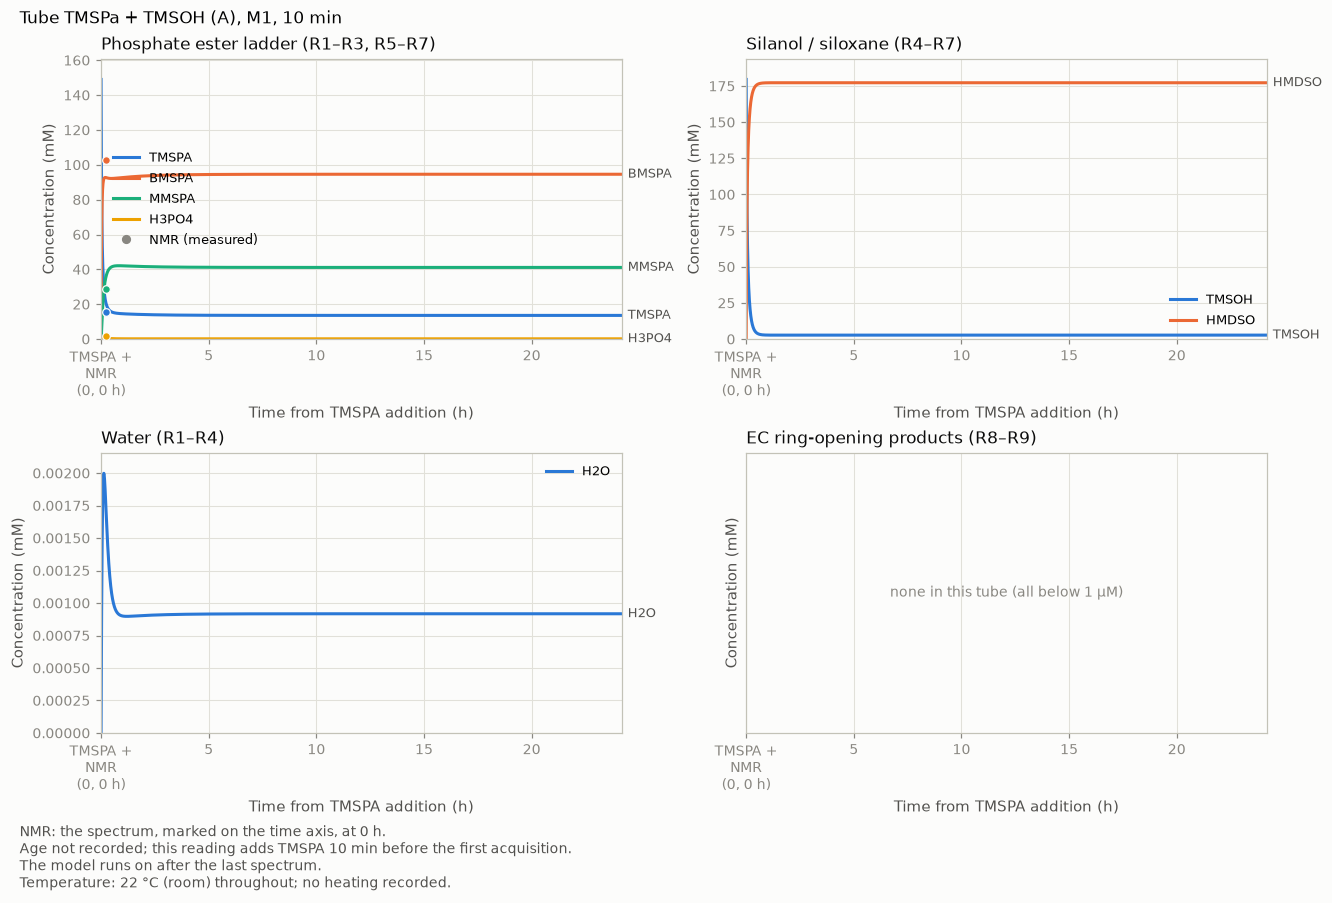

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.2,³¹P,TMSPA,15.7,20.6,+4.8,+0.7
0.2,³¹P,BMSPA,102.7,92.7,-10.0,-1.0
0.2,³¹P,MMSPA,29.0,35.8,+6.8,+1.1
0.2,³¹P,H3PO4,1.5,0.4,-1.1,-0.2


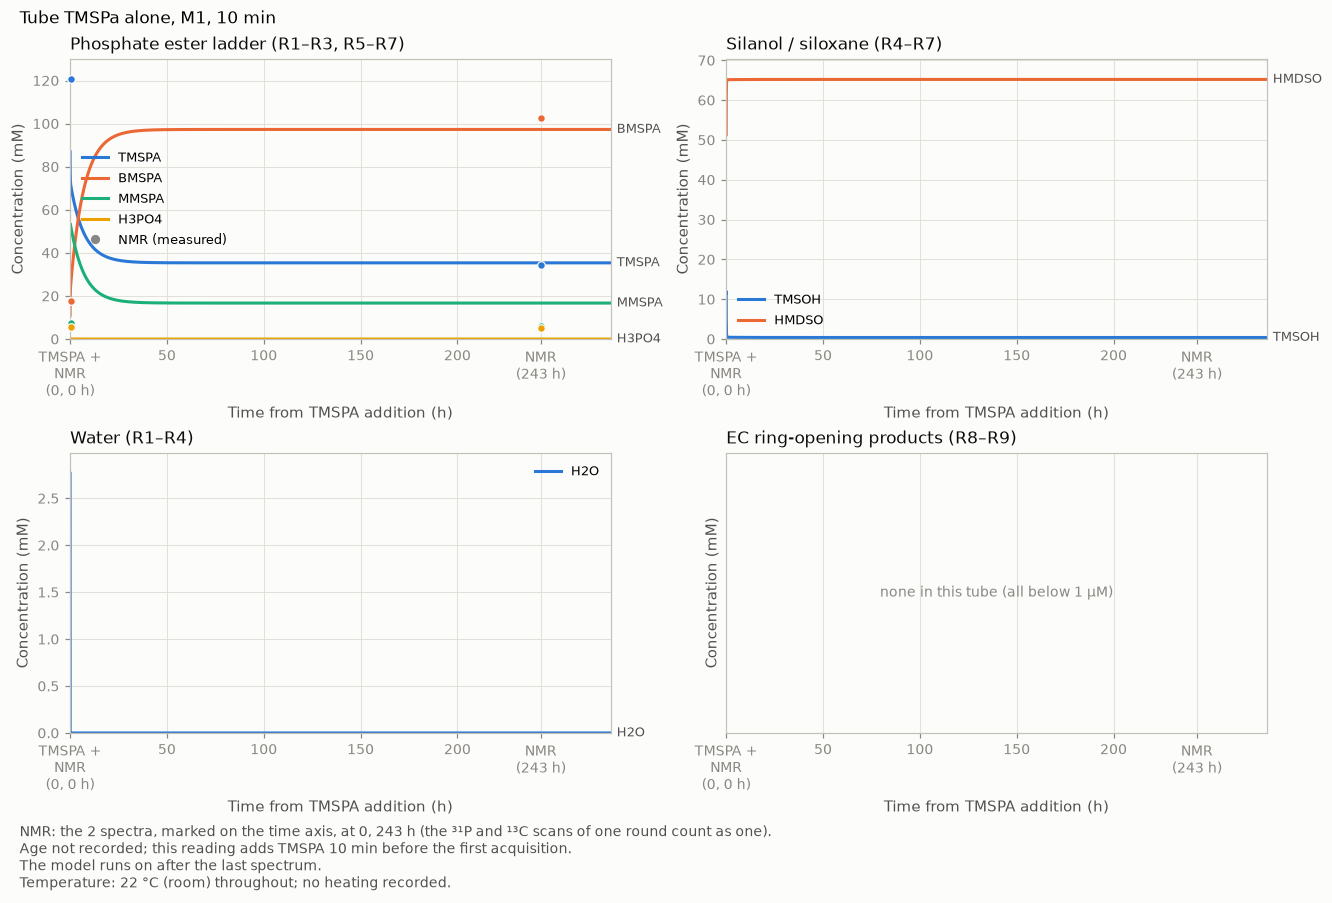

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.2,³¹P,TMSPA,120.5,72.5,-48.0,-4.9
0.2,³¹P,BMSPA,17.7,23.7,+6.0,+0.8
0.2,³¹P,MMSPA,7.4,52.9,+45.5,+6.8
0.2,³¹P,H3PO4,5.4,0.2,-5.2,-0.9
243.0,³¹P,TMSPA,34.6,35.4,+0.8,+0.1
243.0,³¹P,BMSPA,102.8,97.3,-5.5,-0.6
243.0,³¹P,MMSPA,6.2,16.7,+10.5,+1.5
243.0,³¹P,H3PO4,5.1,0.0,-5.1,-0.9


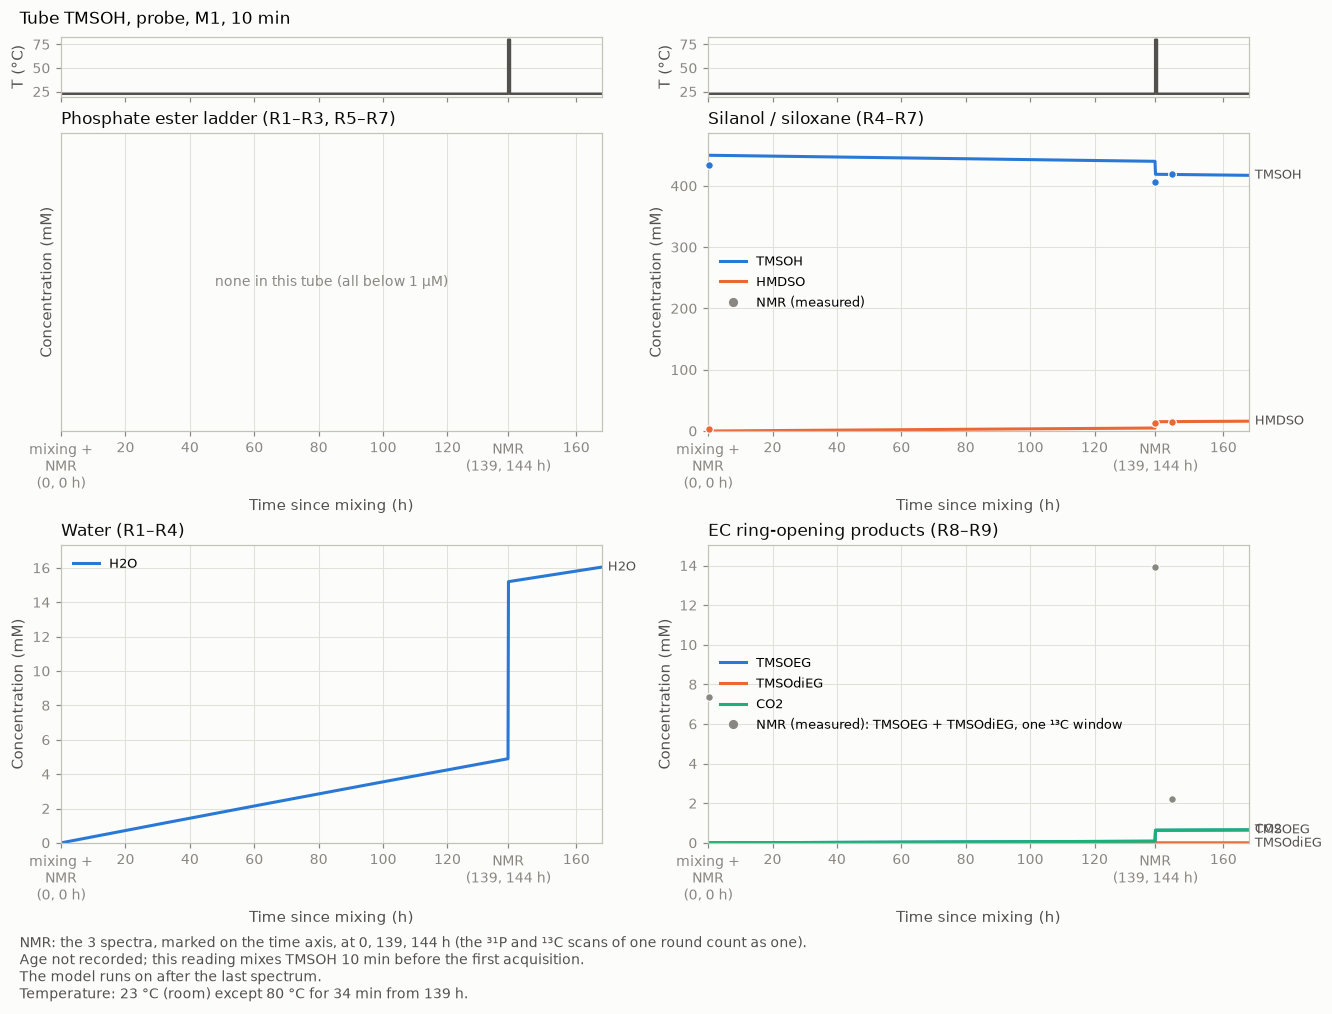

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
0.4,¹³C,TMSOH,433.8,450.0,+16.2,+0.2
0.4,¹³C,HMDSO,7.7,0.0,-7.6,-0.4
0.4,¹³C,TMSOEG (opened EC),7.4,0.0,-7.4,-0.5
138.9,¹³C,TMSOH,405.6,427.1,+21.4,+0.3
138.9,¹³C,HMDSO,25.2,22.5,-2.7,-0.2
138.9,¹³C,TMSOEG (opened EC),13.9,0.4,-13.5,-0.8
144.2,¹³C,TMSOH,419.1,418.6,-0.5,-0.0
144.2,¹³C,HMDSO,28.6,30.7,+2.1,+0.1
144.2,¹³C,TMSOEG (opened EC),2.2,0.6,-1.6,-0.1


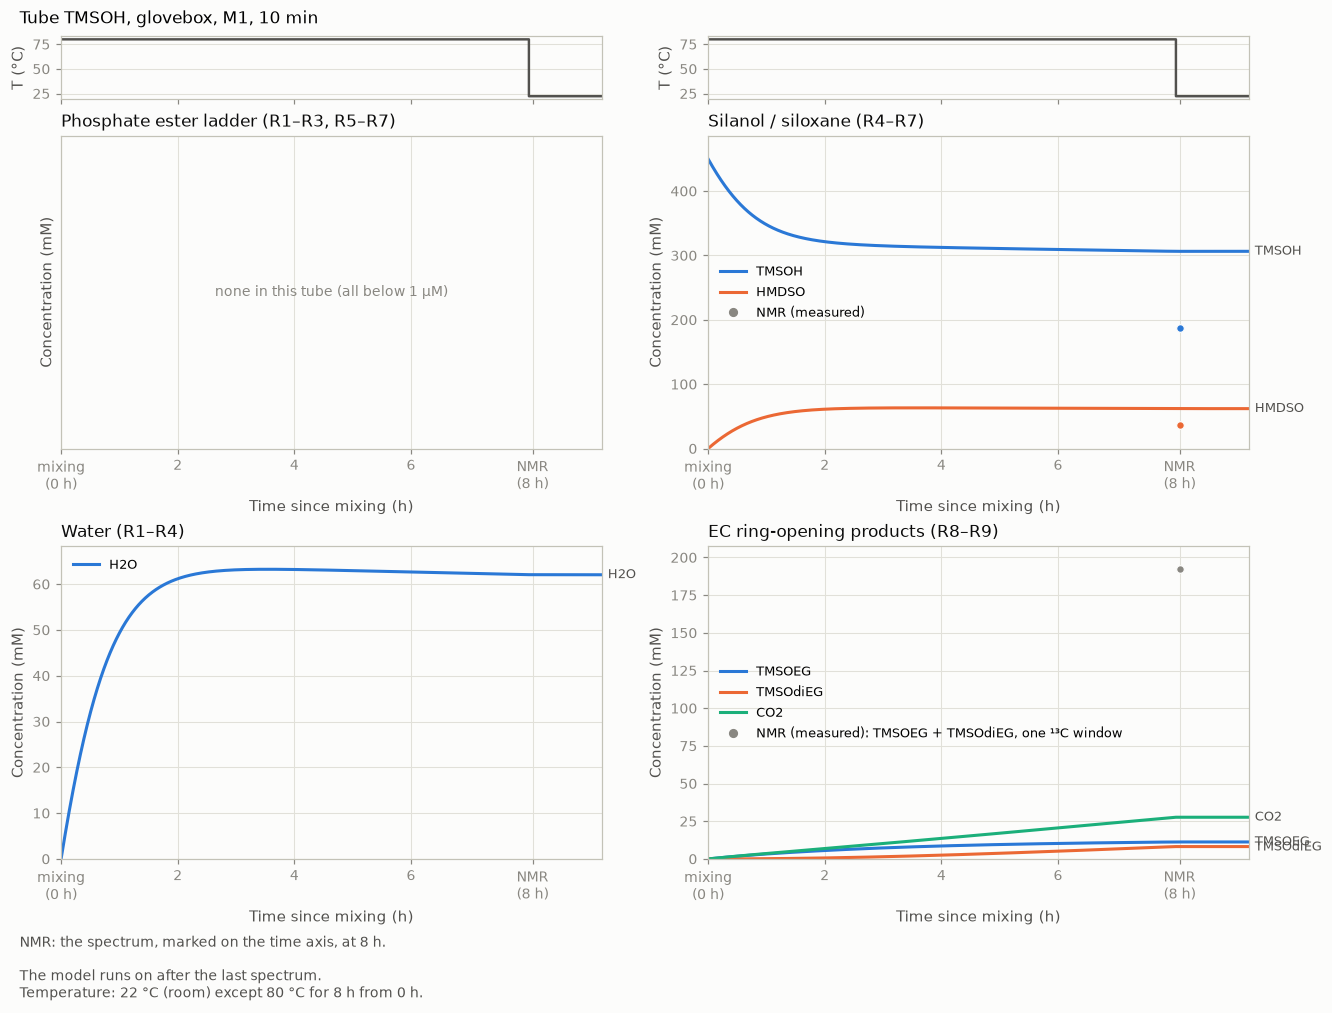

spectrum at (h),nucleus,species,NMR (mM),model (mM),difference (mM),in errors
8.1,¹³C,TMSOH,188.0,306.4,+118.5,+3.9
8.1,¹³C,HMDSO,72.3,124.1,+51.9,+1.8
8.1,¹³C,TMSOEG (opened EC),192.2,19.5,-172.7,-5.0


In [10]:
import matplotlib.pyplot as plt

reading = '10 min'
trajectories = simulate_fit_trajectories(views[reading], until_h=1500.0, t_first_h=1e-4, n_points=4000)
spectrum_times = shares[reading].groupby('sample')['t_h'].unique()
before = {tube: f'Age not recorded; this reading adds TMSPA {reading} before the first acquisition.' for tube in PHOSPHATE_TUBES}
before['TMSOH, probe'] = f'Age not recorded; this reading mixes TMSOH {reading} before the first acquisition.'
for tube in PHOSPHATE_TUBES + ['TMSOH, probe', 'TMSOH, glovebox']:
    fit_plots.plot_tube_concentrations(trajectories, tube, spectrum_times[tube], model=f'{MAIN}, {reading}', before=before.get(tube),
                                       solvent_stage=tube in ('0.5 % H2O', '2 % H2O'), measured=shares[reading])
    plt.show()                                       # the figure first, then its table
    fit_plots.show_tube_comparison(shares[reading], tube)

**What we see**

1. **In M1 nothing waits.** The hydrolysis barrier sits at the lowest value the search allows (0.80 eV, §5.2), so water takes silyl groups off TMSPA in milliseconds: half of the TMSPA is gone after 8 ms in `2 % H2O` and 35 ms in `0.5 % H2O` (§6.1). The vertical steps at `t = 0` are these reactions.

2. **Each water tube then rests where the computed energies and its water put it.** `0.5 % H2O` uses up almost all its water (to about 7 mM) and stops with MMSPA and H₃PO₄. `2 % H2O` keeps about 620 mM of water and stops at H₃PO₄, with its silyl groups as TMSOH (about 400 mM) where the tube shows HMDSO. The 8 h heating steps barely move the phosphate; from 60 °C on they start to open the solvent (TMSOEG), which the tube does not show.

3. **`0.5 % H2O` cannot be reached this way.** `2 % H2O` has no TMSPA left at its first spectrum, minutes after mixing; `0.5 % H2O` has 93 % left 19 h after the first acquisition. With one hydrolysis barrier, four times less water makes the reaction about four times slower (35 ms against 8 ms); a rough count from the two spectra asks for a factor of more than ten thousand.

4. **`TMSPa alone`**: its 65.6 mM of water is used up within a second and takes TMSPA down to about 55 % at once; transfer then turns TMSPA into BMSPA over the next hours. The spectrum 243 h later is described; the first one (81 % TMSPA, 3 min after the addition at 0 min) is not.

5. **`TMSPa + TMSOH (A)`** reacts through transfer in minutes and reaches its measured BMSPA by its spectrum. The two TMSOH tubes change slowly, and only when hot.

6. **The three readings look alike** at this scale: 5 or 10 min move nothing that M1 does in milliseconds or over hours. Only transfer follows them (§5.2).

---

## 3. How a fit is made and scored

**What this part delivers:** the fitted numbers of M1, the path from a set of them to χ², and the rule that says "fits".

**The fitted numbers**

- **g**, the intrinsic barrier of a family of reactions. It sets how fast a reaction goes. M1 fits four, one per family.
- **ΔG_rxn**, the reaction energy. It sets where a reaction stops. M1 does not fit it: every reaction takes its computed value (§5.1).

**From a set of values to χ²**

```mermaid
%%{init: {"themeVariables": {"fontSize": "11px"}}}%%
flowchart TD
    NMR["NMR spectrum"] --> AREAS["peak areas A_i"]
    AREAS --> SHARES["measured shares<br/>s_i ± σ_i"]
    TRIAL["one trial: the four g"] --> MODEL["(1) ΔG‡ from g and the computed ΔG_rxn (Marcus)<br/>(2) k_f, K, k_r<br/>(3) simulate each tube from its recipe<br/>to the time of its spectrum<br/>(4) predicted shares"]
    SHARES --> CHI2["(5) χ²"]
    MODEL --> CHI2
    CHI2 --> OPT["another trial (all four move together), until χ² is smallest"]
```

Measured share

$$s_i = A_i / \sum_j A_j$$

i, j: the peaks of one NMR spectrum (one per species).

(1) Barrier

$$\Delta G^\ddagger = g\,(1 + \Delta G_{rxn}/4g)^2$$

(2) Rate constants

$$k_f = \frac{k_BT}{h}\,e^{-\Delta G^\ddagger/k_BT}, \qquad K = e^{-\Delta G_{rxn}/k_BT}, \qquad k_r = k_f/K$$

(3) Rate, e.g. R3

$$k_f\,[\mathrm{MMSPA}][\mathrm{H_2O}] - k_r\,[\mathrm{H_3PO_4}][\mathrm{TMSOH}]$$

(4) Predicted share, ³¹P

$$\frac{[\mathrm{MMSPA}]}{[\mathrm{TMSPA}]+[\mathrm{BMSPA}]+[\mathrm{MMSPA}]+[\mathrm{H_3PO_4}]}$$

(5) Score

$$\chi^2 = \sum \left(\frac{s_{pred}-s_{meas}}{\sigma_s}\right)^2$$

s_pred, s_meas: predicted and measured share. σ_s: uncertainty of the measured share. The sum runs over every measured share (all tubes, spectra and peaks), with two corrections:

- The shares of one spectrum add up to 1, so a spectrum with K lines holds K − 1 independent values. Each squared miss counts (K − 1)/K of itself: three quarters with four lines.
- The six spectra of `2 % H2O` share part of their error (baseline and floor). That part is counted once for the six, not six times.

So χ² is smaller than the plain sum of the squared misses (§4.1). M1 has no second term for the energies: it does not move them, so it pays nothing for them.

Fixed before any fit:

- The **miss** of one value is (predicted − measured) / error. A model fits when its worst miss is 3 or less.
- χ² adds all the squared misses into one number: it ranks the fits. The worst miss decides.
- Where the error of a share comes from, and whether it is the right size, is the subject of 7.2.

## 4. Where M1 fails, tube by tube

**What this part delivers:** how much of χ² each tube carries, and what the fit becomes when one tube is left out.

### 4.1 χ² and worst miss of each tube

- **χ² of a tube:** its part of the χ² of the fit (§3), computed from the stored fit. The six tubes add up to the χ² of the fit.
- **Worst miss of a tube:** its largest miss, from `fits_residuals.csv`.
- A model fits when no miss is above 3, so one tube is enough to fail it.

In [11]:
# χ² of each tube (tube_chi2, setup cell) and its worst miss, under each reading; where the worst miss is at 0 min
worst = residuals.assign(miss=residuals['z'].abs()).sort_values('miss').groupby(['sample', 'scenario']).tail(1).set_index(['sample', 'scenario'])
tubes = list(tube_chi2.index)
per_tube = pd.concat({'χ²': by_age(tube_chi2), 'worst miss': by_age(worst['miss'].unstack('scenario')).reindex(tubes)}, axis=1)
per_tube[('χ² at 0 min', '% of the fit')] = 100.0 * tube_chi2['0 min'] / tube_chi2['0 min'].sum()
per_tube[('worst miss at 0 min', 'where')] = worst.xs('0 min', level='scenario')['quantity'].reindex(tubes)
per_tube.loc['all tubes'] = [*tube_chi2.sum(), *worst['miss'].groupby(level='scenario').max().reindex(READINGS), 100.0, '']
per_tube.style.format(precision=1)

**What we see**

- **`0.5 % H2O` carries three quarters of χ²** (1879 of 2520 at 0 min) and **`2 % H2O` a fifth** (552): together 96.5 %.
- **Two more tubes fail the rule, by less:** `TMSPa alone` (worst miss 6.8, the MMSPA of its first spectrum) and `TMSOH, glovebox` (5.0, TMSOEG).
- **Two are described:** `TMSPa + TMSOH (A)` (worst miss 1.0 to 1.2) and `TMSOH, probe` (0.8).
- **The readings change nothing that matters:** χ² moves by 0.5 at most between 0, 5 and 10 min, and every tube keeps its worst miss.
- The χ² of `0.5 % H2O` (1879) is three quarters of the sum of its squared misses (2505): its eight shares come from two spectra of four lines each (§3).

### 4.2 Leaving one tube out

**The question:** does M1 fail because of one tube, or everywhere?

- **How:** the fit is made again without each tube in turn, under each reading (with a lighter search than the main fit: 1024 screen points, 8 starts).
- **Table:** χ² and worst miss without each tube, and the four barriers at 0 min. The first row is the fit with every tube.
- **Figure:** how far each barrier moves when a tube is left out (0 min), in meV.

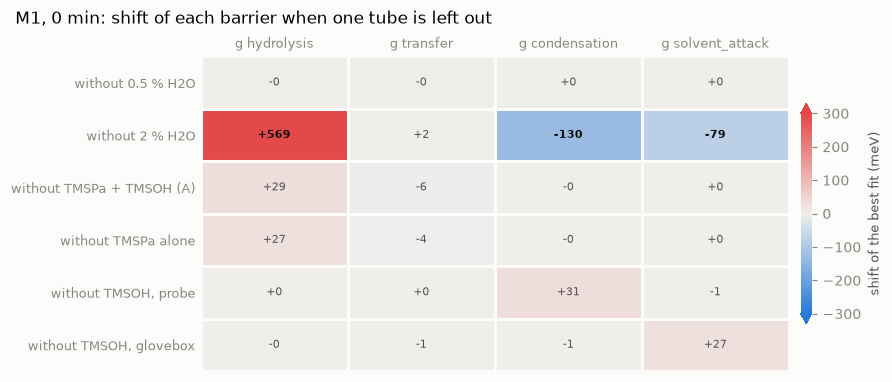

In [12]:
loo = read_main('leave_one_out')
order = list(tube_chi2.index)
without = pd.concat({'χ²': by_age(loo.pivot(index='left out', columns='scenario', values='chi2')),
                     'worst miss': by_age(loo.pivot(index='left out', columns='scenario', values='max |z|'))}, axis=1).reindex(order)
loo_zero = loo[loo['scenario'] == '0 min'].set_index('left out').reindex(order)
without[('0 min', 'where the worst miss is')] = loo_zero['worst']
for name in BARRIER_NAMES:
    without[('0 min', SHORT_NAMES[name])] = loo_zero[name]
everything = [*(fits[s]['chi2'] for s in READINGS), *(fits[s]['max_abs_z'] for s in READINGS),
              summary.set_index('scenario').loc['0 min', 'worst'], *(fits['0 min']['theta'][name] for name in BARRIER_NAMES)]
without = pd.concat([pd.DataFrame([everything], index=['none (the fit)'], columns=without.columns), without.rename(index=lambda tube: f'without {tube}')])
display(without.style.format(precision=2).format(precision=3, subset=[('0 min', SHORT_NAMES[name]) for name in BARRIER_NAMES]))
fit_plots.plot_influence(loo_zero.reset_index(), fits['0 min']['theta'], columns=list(BARRIER_NAMES), clip=300.0,
                         title=f'{MAIN}, 0 min: shift of each barrier when one tube is left out');

**What we see**

- **Without `2 % H2O`** χ² falls from 2520 to 57, and the hydrolysis barrier rises from 0.80 to 1.37 eV: nothing asks for fast hydrolysis any more, and `0.5 % H2O` keeps its TMSPA. M1 still fails, by less: worst miss 5.9 (HMDSO of `TMSOH, probe`), with condensation at the lowest value allowed (1.00 eV).
- **Solvent attack then falls by 79 meV** (to 1.22 eV). With every tube, `2 % H2O` holds about 0.4 M of TMSOH through its 8 h at 60 to 80 °C, and a faster solvent attack would open solvent there that the tube does not show. That holds solvent attack back, and is why `TMSOH, glovebox` gets too little TMSOEG (§2.1); less time at 80 °C in `2 % H2O` does the same (7.3).
- **Without `0.5 % H2O`** the barriers do not move, and χ² is 641 with worst miss 20 (TMSOH of `2 % H2O`): `2 % H2O` alone is out of reach of M1. Its resting composition is not the one the computed energies give (§5.1).
- **Without any other tube** χ² stays above 2380 and the worst miss above 32. Leaving out `TMSPa + TMSOH (A)` at 5 and 10 min lets transfer rise from 0.89–0.90 to 1.32–1.35 eV: that tube is what holds transfer (§5.2).
- **So M1 fails on two separate counts:** the speed of hydrolysis, which `2 % H2O` wants fast and `0.5 % H2O` slow, and the resting composition of `2 % H2O`. Leaving out `2 % H2O` removes both; leaving out `0.5 % H2O` removes only the first.

## 5. Fit

**What this part delivers:** the reaction energies M1 takes as they are, its four barriers, how far the data pin each one, and whether they depend on each other.

### 5.1 Reaction energies: computed, not fitted

- M1 takes every reaction energy from the calculation: DFT in the gas phase, plus the change the solvent brings (MD in EC/DEC 1:1). σ is the uncertainty of the solvent part, the only one the run declares.
- **Table:** the energies of R1–R9 that M1 uses, under every reading. A reaction well below zero runs to the end; one near zero stops partway.

In [13]:
computed = pd.read_csv(RESULTS / 'computed_energies.csv', index_col=0)
used = barriers.pivot_table(index='reaction', columns='scenario', values='dG_rxn_eV')       # the energies the fits ran with
print(f"Largest difference between these energies and those M1 ran with: {used.loc[computed.index].sub(computed['dG_rxn_eV'], axis=0).abs().max().max():.1e} eV")
(computed[['class', 'equation', 'dG_gas_eV', 'ddE_solv_eV', 'dG_rxn_eV', 'sigma_solv_eV', 'K_eq']]
 .rename(columns={'class': 'family', 'equation': 'reaction', 'dG_gas_eV': 'gas phase (eV)', 'ddE_solv_eV': 'solvent (eV)',
                  'dG_rxn_eV': 'ΔG_rxn (eV)', 'sigma_solv_eV': '± σ (eV)', 'K_eq': 'K'}).round(3))

Largest difference between these energies and those M1 ran with: 0.0e+00 eV


,family,reaction,gas phase (eV),solvent (eV),ΔG_rxn (eV),± σ (eV),K
R1,hydrolysis,TMSPA + H2O ⇌ BMSPA + TMSOH,0.139,-0.392,-0.253,0.104,18644.255
R2,hydrolysis,BMSPA + H2O ⇌ MMSPA + TMSOH,0.149,-0.331,-0.182,0.094,1200.449
R3,hydrolysis,MMSPA + H2O ⇌ H3PO4 + TMSOH,0.192,-0.252,-0.061,0.081,10.728
R4,condensation,2 TMSOH ⇌ HMDSO + H2O,-0.132,0.229,0.097,0.120,0.023
R5,transfer,TMSPA + TMSOH ⇌ BMSPA + HMDSO,0.008,-0.163,-0.155,0.111,420.527
R6,transfer,BMSPA + TMSOH ⇌ MMSPA + HMDSO,0.017,-0.102,-0.085,0.102,27.077
R7,transfer,MMSPA + TMSOH ⇌ H3PO4 + HMDSO,0.060,-0.023,0.036,0.090,0.242
R8,solvent_attack,EC + TMSOH ⇌ TMSOEG + CO2,-0.323,0.436,0.113,0.103,0.012
R9,solvent_attack,EC + TMSOEG ⇌ TMSOdiEG + CO2,-0.331,0.316,-0.016,0.106,1.855


**How to read it**

- **Downhill (below zero):** R1, R2, R5 and R6 clearly; R3 and R9 only just. **Uphill:** R4, R7 and R8.
- **R3 is close to zero** (−0.06 eV): its equilibrium lies between MMSPA and H₃PO₄, and the amounts of water and TMSOH decide where.
- **R4 is uphill** (+0.10 eV): where there is water, condensation runs backwards and keeps the silyl groups as TMSOH.

**Where the tube puts the energies: `2 % H2O` by hand**

- A tube that has stopped changing has rate = 0 in step (3) of §3. For R3 that gives
  $K = \dfrac{[\mathrm{H_3PO_4}][\mathrm{TMSOH}]}{[\mathrm{MMSPA}][\mathrm{H_2O}]}$ and $\Delta G_{rxn} = -k_BT \ln K$.
- The cell below does this for `2 % H2O`: concentrations from its measured shares (mean of the six spectra) and its recipe, water from the balance. It sets the result against the computed energy M1 uses.

In [14]:
# The 2 % tube taken as being at equilibrium: K of R2, R3 and R4 from its measured shares and its recipe
kT = KB_EV * 295.65
recipe = observables['samples']['2 % H2O']['c0_M']
mean = residuals[(residuals['scenario'] == '0 min') & (residuals['sample'] == '2 % H2O') & (residuals['kind'] == 'mean')]
share = mean.assign(line=mean['quantity'].str.split(' ').str[0]).set_index('line')['measured']
P, Si = recipe['TMSPA'], 3 * recipe['TMSPA']                       # phosphate and silyl groups in the tube (M)
C = {**{sp: share[sp] * P for sp in ('BMSPA', 'MMSPA', 'H3PO4')}, 'TMSOH': share['TMSOH'] * Si, 'HMDSO': share['HMDSO'] * Si / 2}
released = P * (share['BMSPA'] + 2 * share['MMSPA'] + 3 * share['H3PO4'])     # silyl groups that left the phosphate, one water each
C['H2O'] = recipe['H2O'] - released + C['HMDSO']                              # condensation gives one water back per HMDSO
display(pd.Series({sp: 1000 * c for sp, c in C.items()}).round(0).rename('mM').to_frame().T.rename_axis('2 % H2O, from its shares', axis=1))
K = {'R2': C['MMSPA'] * C['TMSOH'] / (C['BMSPA'] * C['H2O']), 'R3': C['H3PO4'] * C['TMSOH'] / (C['MMSPA'] * C['H2O']),
     'R4': C['HMDSO'] * C['H2O'] / C['TMSOH'] ** 2}
pd.DataFrame({r: {'K from the shares': K[r], '−kT ln K (eV)': -kT * np.log(K[r]), 'computed, used by M1 (eV)': computed.loc[r, 'dG_rxn_eV'],
                  '± σ (eV)': computed.loc[r, 'sigma_solv_eV'],
                  'tube − computed (in σ)': (-kT * np.log(K[r]) - computed.loc[r, 'dG_rxn_eV']) / computed.loc[r, 'sigma_solv_eV']}
              for r in K}).T.round(3)

"2 % H2O, from its shares",BMSPA,MMSPA,H3PO4,TMSOH,HMDSO,H2O
mM,6.0,47.0,99.0,28.0,193.0,848.0


,K from the shares,−kT ln K (eV),"computed, used by M1 (eV)",± σ (eV),tube − computed (in σ)
R2,0.285,0.032,-0.182,0.094,2.284
R3,0.070,0.068,-0.061,0.081,1.597
R4,202.975,-0.135,0.097,0.120,-1.940


**What we see**

- **In all three reactions the tube asks for the other sign:** R2 at +0.03 eV instead of −0.18 eV (2.3σ away), R3 at +0.07 eV instead of −0.06 eV (1.6σ), R4 at −0.14 eV instead of +0.10 eV (1.9σ).
- **What the computed values do to the tube:** with R2 and R3 downhill, the phosphate runs on to H₃PO₄ (0.95 simulated against 0.66 measured). With R4 uphill and about 620 mM of water left, condensation runs backwards and the silyl groups stay as TMSOH (0.85–0.95 simulated against 0.01–0.08 measured). These are the misses of `2 % H2O` in §2.1.
- **Each is within about 2σ of its computed value:** the uncertainty of the solvent part alone allows moves of this size. M1 allows none.
- **The step that can be wrong is the first one, "this tube is at equilibrium".** Its six spectra do not change over six days and through the heating, which is what a tube at rest looks like.

--> The energies say where a tube stops, and M1 cannot move them. 5.2 turns to the barriers.

### 5.2 Barriers: what do the data pin?

**How a profile is made**

1. Take one fitted barrier, for example that of solvent attack.
2. Hold it at a value a little away from its best one and let the fit adjust the other three again. Note how much χ² has risen.
3. Repeat further and further away, on both sides.
4. For a model that fits, the values for which χ² rose by less than 3.84 make a **95 % interval**.

**For M1 this is not a confidence interval.** M1 does not fit: its χ² is about 2520 for 80 values. A rise of 3.84 on top of that is not a probability. A profile still says which barriers the data pin (χ² climbs fast on both sides), which ones they leave open, and how χ² moves. The ranges below are drawn as in the other notebooks, but they read "where χ² stays within 3.84 of the best M1", not "where the barrier is".

- **Figure:** three barriers at 0 min. Blue line: the rise of χ². Grey: where it stays below 3.84.

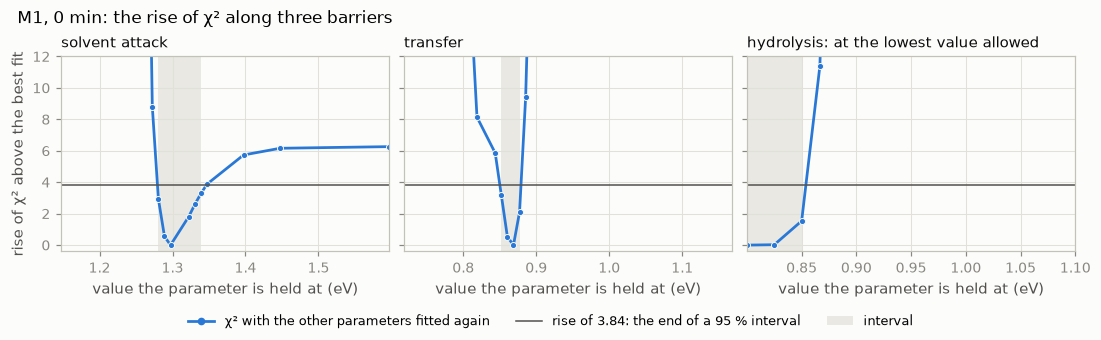

In [15]:
if profiles:
    fit_plots.plot_profile_cases(profiles['0 min'], {'g solvent_attack': 'solvent attack', 'g transfer': 'transfer',
                                                     'g hydrolysis': 'hydrolysis: at the lowest value allowed'},
                                 title=f'{MAIN}, 0 min: the rise of χ² along three barriers');
else:
    print('No profiles in this run (the night stage did not run).')

**How to read it**

- **Left, solvent attack:** χ² climbs steeply below the best value (1.30 eV) and slowly above it: at 1.6 eV it has risen by about 6 only.
- **Middle, transfer:** χ² climbs fast on both sides: the data pin it to a narrow range, 0.85–0.88 eV.
- **Right, hydrolysis:** the best value is the lowest the search allows, 0.80 eV. χ² rises only upwards, and steeply: by 11 at 0.87 eV, by 216 at 0.90 eV and by thousands above 0.95 eV. The data push hydrolysis against the lower wall; below it nothing was tried.

**All four barriers**

- **Figure:** the same for every barrier, under the three readings. Dot: best fit. Bar (labelled "95 % interval" by the plotting function): where χ² stays within 3.84. Arrow: a side with no limit inside the range tried. Pale track: the range the search was allowed.
- **On the axis:** g, the number the fit moves.
- **Tables:** the same ranges as numbers; ΔG‡ of each reaction for the best fits, which is g corrected by the reaction energy (step 1 of §3) and is what sets the rate (N15 and N12 take the hydrolysis barrier); and the profiles of hydrolysis and transfer at 0 min made again with a solver 100 times tighter.

χ² within 3.84 of the best fit (eV),0 min,5 min,10 min
barrier condensation,1.105–1.187,1.105–1.187,1.105–1.187
barrier hydrolysis,≤ 0.856,≤ 0.870,≤ 0.878
barrier solvent attack,1.279–1.347,1.279–1.346,1.279–1.346
barrier transfer,0.850–0.880,0.862–0.901,0.870–0.917


reading,0 min,5 min,10 min
ΔG‡ of the best fit (eV),,,
R1 · first hydrolysis,0.68,0.68,0.68
N15,0.64,0.64,0.64
R2 · second hydrolysis,0.71,0.71,0.71
N12,0.73,0.73,0.73
R3 · third hydrolysis,0.77,0.77,0.77
R5 · first transfer,0.79,0.81,0.83
R4 · condensation,1.18,1.18,1.18
R8 · solvent attack,1.35,1.35,1.35


0 min: range edges at the solver tolerance of the run (1e-6) and at 1e-8,"low, rtol 1e-6","low, rtol 1e-8","high, rtol 1e-6","high, rtol 1e-8"
parameter,,,,
barrier hydrolysis,NaN,NaN,0.856,0.856
barrier transfer,0.85,0.85,0.880,0.880


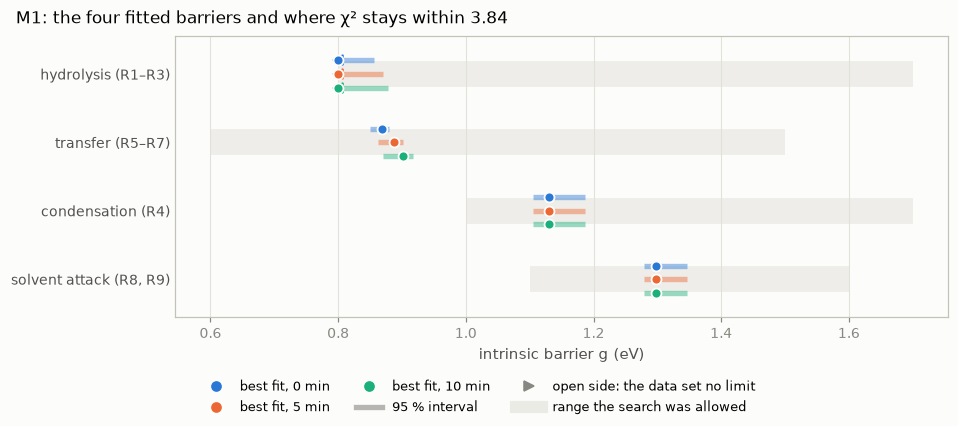

In [16]:
if profiles:
    fit_plots.plot_parameter_intervals(parameters, intervals, structure=MAIN, names=BARRIER_NAMES, boxes={name: BARRIER_BOX_EV[name[2:]] for name in BARRIER_NAMES},
                                       scenarios=READINGS, xlabel='intrinsic barrier g (eV)', title=f'{MAIN}: the four fitted barriers and where χ² stays within 3.84');
    display(tables.format_interval_table(intervals, MAIN, scenarios=READINGS).rename(index=SHORT_NAMES).rename(columns=AGES)
            .rename_axis('χ² within 3.84 of the best fit (eV)', axis=1))
    display(by_age(barriers.pivot(index='reaction', columns='scenario', values='dG_barrier_eV')).loc[['R1', 'N15', 'R2', 'N12', 'R3', 'R5', 'R4', 'R8']].round(2)
            .rename(index=fit_plots.REACTION_LABELS).rename_axis(index='ΔG‡ of the best fit (eV)'))
    tolerance = read_main('tolerance_check', complete=False)
    display(tolerance.set_index('parameter').rename(index=SHORT_NAMES)[['low, rtol 1e-6', 'low, rtol 1e-8', 'high, rtol 1e-6', 'high, rtol 1e-8']]
            .round(3).rename_axis('0 min: range edges at the solver tolerance of the run (1e-6) and at 1e-8', axis=1))
else:
    print('No profiles in this run (the night stage did not run): no ranges to show.')

**What we see**

| Barrier | Best fit (0 / 5 / 10 min) | χ² within 3.84 | What the data do |
|---|---|---|---|
| hydrolysis | 0.80 eV in all three, the lowest allowed | ≤ 0.856, ≤ 0.870, ≤ 0.878 eV | push it against the wall: as fast as allowed |
| transfer | 0.869, 0.888, 0.902 eV | 0.850–0.880, 0.862–0.901, 0.870–0.917 eV | pin it, and it follows the reading |
| condensation | 1.130 eV | 1.105–1.187 eV | pin it on both sides |
| solvent attack | 1.297 eV | 1.279–1.347 eV | pin it from below, loosely from above |

- **Transfer follows the reading.** `TMSPa + TMSOH (A)` has to reach its measured BMSPA by its first spectrum, and the later the reading puts that spectrum, the slower transfer can be (4.2: without that tube transfer moves to 1.32 eV at 5 min and 1.35 eV at 10 min). It is the only number the readings move.
- **The fastest step is N15** (TMSPA + H₂O → MMSPA + HMDSO, ΔG‡ 0.64 eV), then R1 (0.68 eV). At room temperature they empty the water tubes in milliseconds (§6.1).
- **The tighter solver gives the same edges** for hydrolysis and transfer: the profiles are not an artefact of the solver.
- These ranges describe a model that does not fit. They say what the tubes demand of M1, not where the barriers are.

--> 5.3 asks whether the four barriers can be moved independently.

### 5.3 Do the fitted numbers depend on each other?

- **What is computed:** the correlation between every pair of the four barriers, at the best fit of each reading (figure: 0 min).
- **What a correlation means here:** push one number up a little and re-fit. If a second number has to follow it up, the two are correlated (+1, red). If it has to go down, they are anti-correlated (−1, blue). If it does not care, the correlation is 0 (grey).
- **Why it matters:** two numbers with a correlation near ±1 are not two results. The data fix one combination of them.
- **Limit:** this is a local picture, valid close to the best fit. The hydrolysis barrier sits on the lowest value it is allowed, where the fit cannot push it further down; for it the correlation shows the direction of a trade, not its size.

,0 min,5 min,10 min
the same pairs under the three readings,,,
hydrolysis against transfer,-0.83,-0.86,-0.78
"condensation against any other, largest",0.00,0.00,0.00
"solvent attack against any other, largest",0.05,0.06,0.08


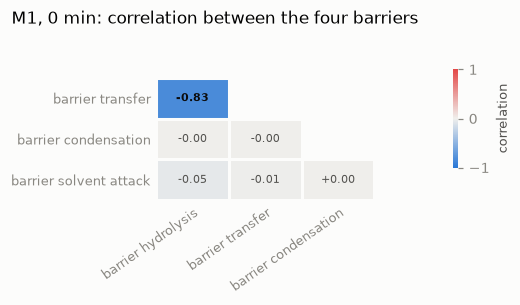

In [17]:
correlation = {scenario: calculate_parameter_correlation(fits[scenario], observables)['correlation'] for scenario in READINGS}
fit_plots.plot_correlation(correlation['0 min'], labels=SHORT_NAMES, title=f'{MAIN}, 0 min: correlation between the four barriers');
pairs = {'hydrolysis against transfer': ('g hydrolysis', 'g transfer'), 'condensation against any other, largest': ('g condensation', None),
         'solvent attack against any other, largest': ('g solvent_attack', None)}
pd.DataFrame({AGES[scenario]: {label: matrix.loc[a, b] if b else matrix.loc[a].drop(a).abs().max() for label, (a, b) in pairs.items()}
              for scenario, matrix in correlation.items()}).round(2).rename_axis('the same pairs under the three readings')

**What we see**

- **Hydrolysis and transfer trade against each other** (−0.83 at 0 min, −0.78 to −0.86 under the three readings): TMSPA can be consumed by water or by TMSOH, and lowering one barrier lets the other rise. With hydrolysis at its lower wall the trade can only go one way: hydrolysis up, transfer down.
- **Condensation and solvent attack stand alone** (0.08 at most): no other barrier can compensate for them.

--> Four barriers, but the data fix two of them alone and one combination of the other two. §6 turns to the age.

## 6. The unknown age

**What this part delivers:** what the readings assume, what M1 does in the first minutes after mixing, and what a trace of TMSOH at mixing does.

### 6.1 The readings, and the first minutes

- **Age:** the time between mixing a tube and recording its first spectrum. Nobody wrote it down. Only `TMSOH, glovebox` comes with a history, taken from the paper.
- **Why it matters:** most tubes give one composition. A composition says how far a reaction has gone, not how long it took. "Slow reaction, old tube" and "fast reaction, young tube" give the same spectrum, so every barrier that sets a speed depends on the age that is assumed.
- **This fit:** the age is taken as near zero. TMSPA was added just before the tube went into the spectrometer.

| Name in the result files | Reading |
|---|---|
| `0 min` | TMSPA added at the first acquisition (the reference model's t = 0, at the first NMR) |
| `5 min` | TMSPA added 5 min before the first acquisition |
| `10 min` | TMSPA added 10 min before the first acquisition |

- **How to use them:** a result that is the same under every reading is set by the data. A result that changes with the reading is set by the assumption.
- **Figure:** the TMSPA share of the three tubes mixed with TMSPA and no TMSOH, from mixing on (the time axis starts at 0.36 ms), for the best fit under each reading. A marker is a measured share, placed where the reading puts its spectrum.
- **Table:** seconds from adding TMSPA until half of it is gone.

reading,0 min,5 min,10 min
seconds until half of the TMSPA is gone,,,
0.5 % H2O,0.035,0.035,0.035
2 % H2O,0.008,0.008,0.008
TMSPa alone,115.006,238.139,407.828


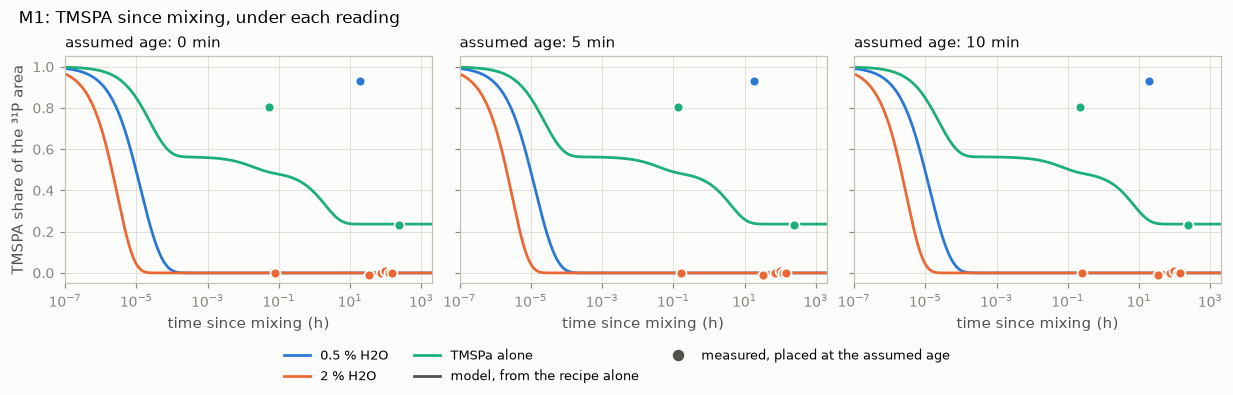

In [18]:
reading_views = {scenario: tabulate_window_amounts(simulate_fit_trajectories(views[scenario], until_h=2000.0, t_first_h=1e-7, n_points=1500), '31P')
                 for scenario in READINGS}
fit_plots.plot_reading_trajectories(reading_views, shares, samples=WAITING_TUBES, x_range=(1e-7, 2000.0),
                                    title=f'{MAIN}: TMSPA since mixing, under each reading');


def tabulate_half_times(curves):
    # Seconds from adding TMSPA until the TMSPA share first falls below one half, per tube and reading
    rows = {}
    for scenario, curve in curves.items():
        share = curve['TMSPA'] / curve[['TMSPA', 'BMSPA', 'MMSPA', 'H3PO4']].sum(axis=1)
        rows[scenario] = 3600.0 * curve[share < 0.5].groupby('sample')['t_h'].min()
    return by_age(pd.DataFrame(rows)).loc[WAITING_TUBES].round(3)


tabulate_half_times(reading_views).rename_axis(index='seconds until half of the TMSPA is gone')

**How to read it**

- Each curve is a tube according to the model. Each marker has to sit on the curve of its colour.
- Moving a marker left or right is what "assuming another age" means. Here the three readings move the markers by minutes at most.

**What we see**

- **The two water tubes lose their TMSPA in milliseconds** (half gone after 8 ms in `2 % H2O`, 35 ms in `0.5 % H2O`) under every reading. The markers of `2 % H2O` (no TMSPA) sit on their curve; that of `0.5 % H2O` (93 % TMSPA at 19 h) lies far above it.
- **`TMSPa alone` falls in two steps:** to about 55 % within a second, while its 65.6 mM of water lasts, then slowly, through transfer, to 24 % within a day. Its second marker (243 h) sits on the curve; its first (81 %, minutes after mixing) lies above it.
- **The readings only move `TMSPa alone`:** half of its TMSPA is gone after 115 s at 0 min, 238 s at 5 min and 408 s at 10 min, because transfer is slower in the later readings (§5.2). The curve moves with the marker, so the miss stays.
- **Why the age hardly matters to M1:** it does in milliseconds what the readings move by minutes. An age of minutes cannot keep TMSPA in a tube that M1 empties in a second.

--> 6.2 asks whether TMSOH present at mixing would change this.

### 6.2 A trace of TMSOH at mixing

**Context**

- **What every fit assumes:** a tube starts from its recipe alone. No TMSOH is there at mixing.
- **Why doubt it:** the first spectrum of `TMSPa alone` already shows 12 % BMSPA, and `0.5 % H2O` shows 6 %. Each BMSPA has released a silyl group. A TMSPA stock that has seen moisture would hold some of these products before it is mixed.
- **Why it can matter:** in a model where the first TMSOH starts a chain of reactions, a trace at mixing starts the chain earlier.

**Test**

- The fitted barriers are kept as they are. TMSOH is added at mixing to the three tubes of 6.1, from 1 nM to 1 mM (1 mM is 0.7 % of the TMSPA).
- **Trace rule of the run:** a fit is accepted only if it still fits (worst miss 3 or less) with 1 µM and with 1 mM. The rule is applied only to a fit that fits, so `trace_verdict.csv` holds no row of M1. The scan itself (`trace_sensitivity.csv`) is made for every fit.
- **Table and first figure:** the worst miss with each trace. **Second figure:** the curves of 6.1, with 1 mM as dashed lines.

trace_verdict.csv: 0 rows of M1 (the rule is applied to the fits that fit, and M1 fits under no reading)


reading,0 min,5 min,10 min
"worst miss, barriers unchanged",,,
0 µM,41.73,41.73,41.73
0.001 µM,41.73,41.73,41.73
0.1 µM,41.73,41.73,41.73
1 µM,41.73,41.73,41.73
10 µM,41.73,41.73,41.73
100 µM,41.72,41.72,41.72
1000 µM,41.69,41.69,41.69


reading,0 min,5 min,10 min
with 1 mM TMSOH: seconds until half of the TMSPA is gone,,,
0.5 % H2O,0.035,0.035,0.035
2 % H2O,0.008,0.008,0.008
TMSPa alone,96.634,200.097,342.678


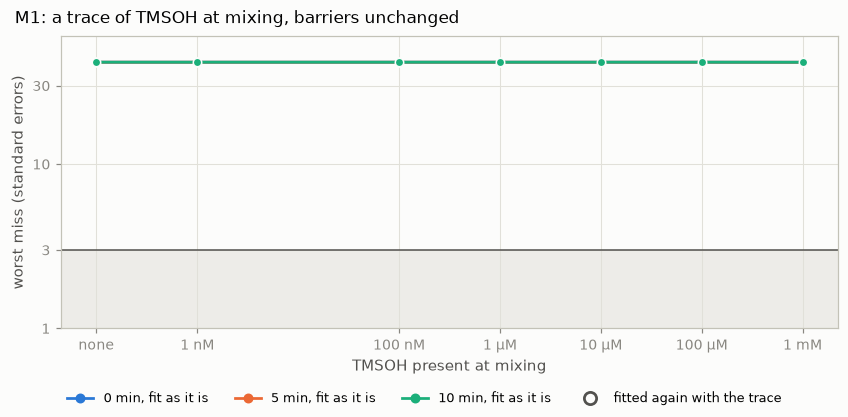

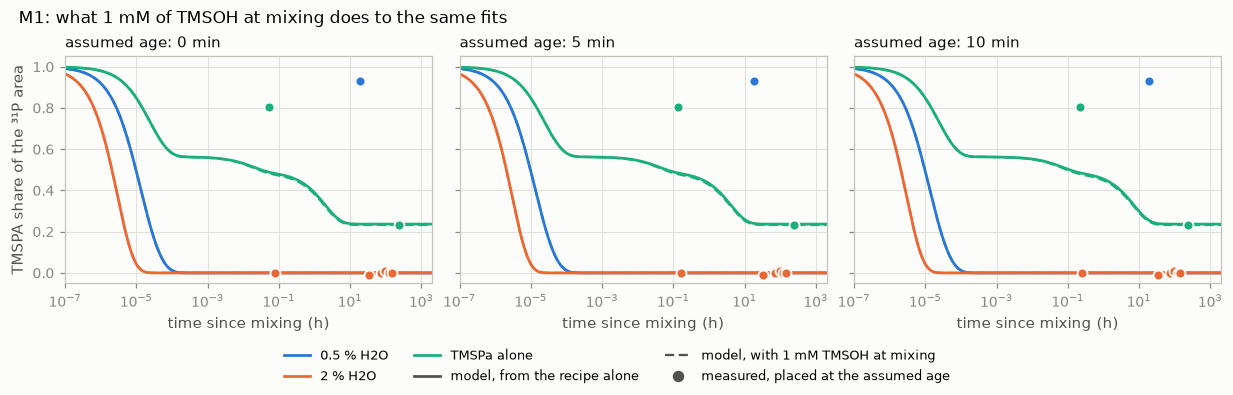

In [19]:
verdict = read_main('trace_verdict', complete=False)
print(f'trace_verdict.csv: {len(verdict)} rows of {MAIN} (the rule is applied to the fits that fit, and {MAIN} fits under no reading)')
traces = read_main('trace_sensitivity')
display(by_age(traces.pivot(index='TMSOH at mixing (M)', columns='scenario', values='max |z|')).round(2)
        .rename(index=lambda level: f'{1e6 * level:g} µM').rename_axis(index='worst miss, barriers unchanged'))
fit_plots.plot_trace_scan(traces, scenarios=READINGS, title=f'{MAIN}: a trace of TMSOH at mixing, barriers unchanged');
trace = {tube: {'added_M': {'TMSOH': 1e-3}} for tube in WAITING_TUBES}      # on top of the run's own (the water of TMSPa alone stays)
traced = {scenario: evaluate_fit(fits[scenario], observables, overrides=trace, ages=views[scenario]['ages']) for scenario in READINGS}
traced_views = {scenario: tabulate_window_amounts(simulate_fit_trajectories(view, until_h=2000.0, t_first_h=1e-7, n_points=1500), '31P')
                for scenario, view in traced.items()}
fit_plots.plot_reading_trajectories(reading_views, shares, samples=WAITING_TUBES, traced=traced_views, trace_label='model, with 1 mM TMSOH at mixing',
                                    x_range=(1e-7, 2000.0), title=f'{MAIN}: what 1 mM of TMSOH at mixing does to the same fits');
tabulate_half_times(traced_views).rename_axis(index='with 1 mM TMSOH: seconds until half of the TMSPA is gone')

**What we see**

- **A trace of TMSOH changes nothing that matters:** the worst miss goes from 41.73 to 41.69 with 1 mM, under every reading. The three lines of the first figure lie on top of one another.
- **Why:** in M1 water does the work, within milliseconds, and needs no TMSOH to start. 1 mM of TMSOH only speeds up the second, slow step of `TMSPa alone` (half of its TMSPA gone after 97 s instead of 115 s at 0 min).
- **The trace rule** is not applied to M1: no reading fits, so M1 is rejected by the fit rule before the trace rule is reached.

--> M1 has no wait that a trace could shorten. §7 checks the tools: the method and the error bars.

## 7. Can the method and the error bars be trusted?

**What this part delivers:** a test of the fitting method on data whose answer is known, a look at the error of a share, and the fit made again with other declared choices.

### 7.1 The method on invented data

**The idea**

1. Choose a set of barriers and call it the truth.
2. Let the model make the shares that the lab tubes would show with that truth: same tubes, same times, same errors. Add random noise of the size of the errors.
3. Hand these invented shares to the fit, without the answer.
4. Compare what comes back with the truth.

- If the method works, the fitted values land near the truth and the 95 % intervals contain it (about 19 times in 20).
- If a number comes back as "not determined" here, where the model is right by construction, the tubes cannot determine it. A fit of the lab data cannot be expected to do better.
- On invented data M1 is the right model, so here the intervals are real 95 % intervals.

**The case of M1** (the run has one case per model; only this one is shown)

| Case | Model that made the data | Truth | Reading | Data sets |
|---|---|---|---|---|
| `M1 0 min` | M1 | the M1 fit of the lab data at 0 min | 0 min | 2 (seeds 1 and 2) |

- **First table:** per data set, χ² of the fit against χ² of the true numbers, and how many true values lie inside their interval.
- **Figure:** fitted value minus true value, for every barrier and data set. Everything should sit on the black line, and every bar should cross it. **Last table:** the same in numbers.

,χ² of the fit,χ² of the true numbers,true values inside their interval,intervals,optimiser converged
case,,,,,
"M1 0 min, seed 1",44.1,44.8,4,4,True
"M1 0 min, seed 2",56.6,58.9,4,4,True


truth    fit    low   high  \
case             parameter                                            
M1 0 min, seed 1 barrier hydrolysis      0.800  0.810    NaN  0.846   
                 barrier transfer        0.869  0.868  0.852  0.879   
                 barrier condensation    1.130  1.120  1.100  1.168   
                 barrier solvent attack  1.297  1.294  1.279  1.337   
M1 0 min, seed 2 barrier hydrolysis      0.800  0.830    NaN  0.857   
                 barrier transfer        0.869  0.866  0.851  0.878   
                 barrier condensation    1.130  1.143  1.113  1.189   
                 barrier solvent attack  1.297  1.317  1.290    NaN   

                                                   status  truth inside  
case             parameter                                               
M1 0 min, seed 1 barrier hydrolysis      upper bound only          True  
                 barrier transfer                interval          True  
                 barrier condensation            interval          True  
                 barrier solvent attack          interval          True  
M1 0 min, seed 2 barrier hydrolysis      upper bound only          True  
                 barrier transfer                interval          True  
                 barrier condensation            interval          True  
                 barrier solvent attack  lower bound only          True

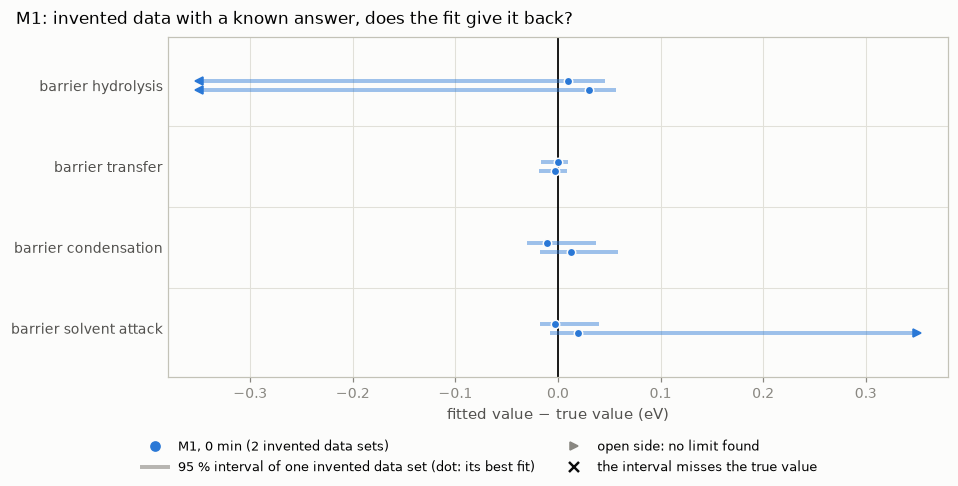

In [20]:
recovery = read_main('recovery_summary')
recovery = recovery[recovery['case'].str.startswith(f'{MAIN} 0 min')]          # the case of M1
display(recovery.groupby('case').agg(**{'χ² of the fit': ('chi2 fit', 'first'), 'χ² of the true numbers': ('chi2 truth', 'first'),
                                        'true values inside their interval': ('truth inside', 'sum'), 'intervals': ('truth inside', 'size'),
                                        'optimiser converged': ('optimiser ok', 'all')}).round(1))
fit_plots.plot_recovery_offsets(recovery, names={name: SHORT_NAMES[name] for name in BARRIER_NAMES},
                                cases={f'{MAIN} 0 min': f'{MAIN}, 0 min (2 invented data sets)'},
                                title=f'{MAIN}: invented data with a known answer, does the fit give it back?');
recovery.set_index(['case', 'parameter'])[['truth', 'fit', 'low', 'high', 'status', 'truth inside']].rename(index=SHORT_NAMES).round(3)

**How to read it**

- **Narrow bars on the line:** the number is found, and found precisely. **Wide bars or arrows:** the tubes do not determine it, even with the right model.
- **A cross:** the interval excludes the truth.

**What we see**

- **The search works:** in both data sets the fit reaches a χ² below that of the true numbers (44.1 against 44.8, 56.6 against 58.9).
- **All 8 true values lie inside their interval.**
- **Found, and precisely:** transfer (to about ±0.015 eV) and condensation (to about ±0.04 eV).
- **Hydrolysis: an upper limit only** (≤ 0.846 and ≤ 0.857 eV). The truth is 0.80 eV, the lowest value the search allows, so the lower side cannot close: this is the wall of §5.2, not a weakness of the method.
- **Solvent attack:** closed in one data set (1.279–1.337 eV), open above in the other.
- **χ² of a fitting model:** 44 and 57 for 80 values, below the 76 expected (the errors are on the large side, 7.2). M1 on the lab data has 2520.

**What this means**

- The method finds the barriers of M1 when M1 is the truth. The failure on the lab data is the model's, not the search's.

--> 7.2 looks at the errors that every miss is measured in.

### 7.2 The error of a share: what is declared, what is checked

**Why this matters:** every miss is a difference divided by an error. If the errors are too small, a good model fails the rule; if they are too large, a wrong model passes.

**What the error of a share is made of**

| Part | Where it comes from | Declared or measured |
|---|---|---|
| noise | the scatter of the spectrum where there is no line | measured, per spectrum |
| baseline | the share is computed with three different baselines; half their spread | measured, per spectrum |
| floor | what the two parts above cannot see (lines that relax or are enhanced differently). ³¹P: the larger of 0.01 and 5 % of the share. ¹³C: the larger of 0.03 and 15 % | **declared** before any fit |

- The three are added in quadrature.
- **Figure:** the size of each part, one dot per measured share.

,noise (measured),baseline (measured),floor (declared),all three together
median error of a share,,,,
13C,0.014,0.020,0.03,0.053
31P,0.005,0.012,0.01,0.032


,floor (declared),baseline (measured),noise (measured)
shares in which this part is the largest,45,25,10


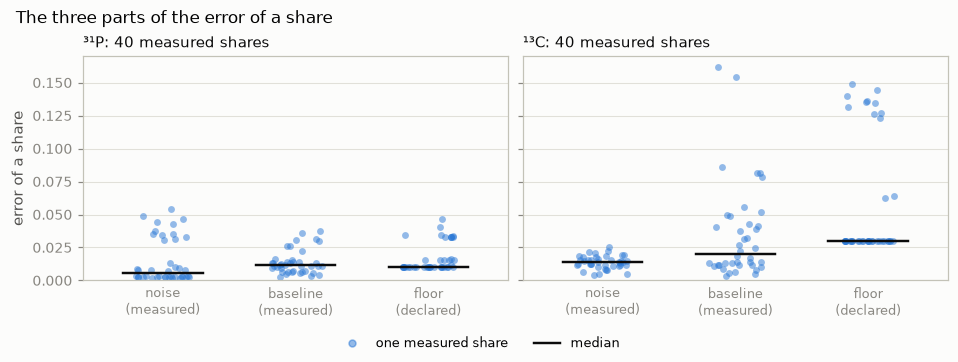

In [21]:
measured = tabulate_observable_shares(observables).query("role == 'fit'").copy()
floor = observables['_meta']['error_floor']
measured['floor'] = [max(floor[n]['absolute'], floor[n]['relative'] * max(s, 0.0)) for n, s in zip(measured['nucleus'], measured['share'])]
parts = {'sigma_noise': 'noise\n(measured)', 'sigma_baseline': 'baseline\n(measured)', 'floor': 'floor\n(declared)'}
fit_plots.plot_error_parts(measured, parts=parts, title='The three parts of the error of a share');
measured['total'] = np.sqrt((measured[list(parts)] ** 2).sum(axis=1))
names = {**{column: label.replace('\n', ' ') for column, label in parts.items()}, 'total': 'all three together'}
display(measured.groupby('nucleus')[list(names)].median().rename(columns=names).round(3).rename_axis('median error of a share'))
measured[list(parts)].idxmax(axis=1).map(names).value_counts().rename('shares in which this part is the largest').to_frame().T

**What we see**

- **The declared floor is the largest part in more than half of the shares** (45 of 80). The error bars are to a large extent a declaration, not a measurement.
- The measured parts are of the same order. Together the three give a share an error of about 0.03 on ³¹P and 0.05 on ¹³C (medians; a share runs from 0 to 1).

**Check 1: the same tube measured six times**

- `2 % H2O` was measured six times at room temperature and its composition did not change. The six spectra are six tries at the same shares.
- **Figure:** each share minus the mean of its six values. The bar is the noise of that spectrum.
- **How to read:** if noise were the whole story, about two bars in three would cross the zero line.

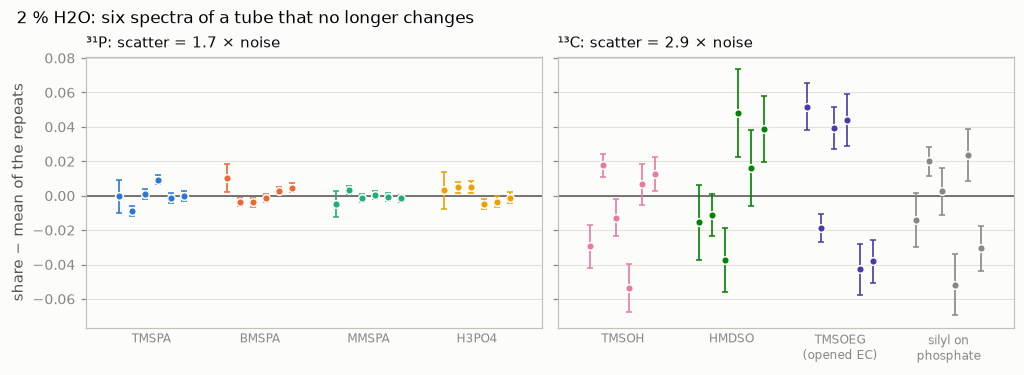

In [22]:
scatter = {nucleus: calculate_replicate_scatter(observables, '2 % H2O', nucleus)['birge'] for nucleus in ('31P', '13C')}
fit_plots.plot_replicates(measured, sample='2 % H2O', scatter=scatter, title='2 % H2O: six spectra of a tube that no longer changes');

- **The six values scatter more than their noise:** 1.7 times on ³¹P and 2.9 times on ¹³C. Something besides noise changes from spectrum to spectrum (the baseline, for example).
- **What the fit does with this:** for this tube the noise is multiplied by these factors. It is the only tube where the error can be checked this way; the others have one spectrum.

**Check 2: are the misses as large as the errors say?**

- If the errors are right and the model is right, the misses of a fit scatter like a bell curve of width 1: two in three within ±1, χ² close to the number of values minus the number of fitted numbers.
- M1 is not right (§4), so this check cannot judge the errors here. It shows how the misses of a model that fails are spread, and whether the errors could explain the failure.
- **Figure:** the misses of the 0 min fit against that curve (88 rows: the 80 values, with the "no change" of `2 % H2O` listed for each of its spectra). The axis stops at ±4.
- **Table:** the same fitted numbers scored with the declared floor removed, as it is, and doubled (not fitted again; 7.3 fits again).

60% of the misses are within ±1 (bell curve: 68 %); 16 of 88 are above 3 (7 in 0.5 % H2O, 5 in 2 % H2O, 2 in TMSPa alone, 2 in TMSOH, glovebox), 13 of them outside the axis (largest 41.7).
χ² = 2519.7 for 80 values and 4 fitted numbers (expected for a model that fits: about 76).


,χ²,worst miss,where the worst miss is,fits
"same fitted numbers, 0 min",,,,
floor removed,12051.4,59.5,0.5 % H2O: P-silyl,no
floor as declared,2519.7,41.7,0.5 % H2O: MMSPA,no
floor doubled,1094.5,28.8,0.5 % H2O: MMSPA,no


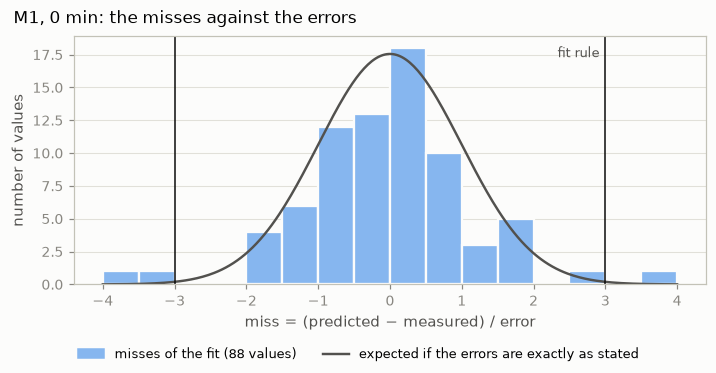

In [23]:
table = fits['0 min']['table']
fit_plots.plot_miss_distribution(table, title=f'{MAIN}, 0 min: the misses against the errors');
within, beyond = (table['z'].abs() < 1.0).mean(), table['z'].abs() > 3.0
print(f"{within:.0%} of the misses are within ±1 (bell curve: 68 %); {beyond.sum()} of {len(table)} are above 3 "
      f"({', '.join(f'{n} in {tube}' for tube, n in table.loc[beyond, 'sample'].value_counts().items())}), "
      f"{(table['z'].abs() > 4.0).sum()} of them outside the axis (largest {table['z'].abs().max():.1f}).")
print(f"χ² = {fits['0 min']['chi2']:.1f} for {fits['0 min']['n_residuals']} values and {fits['0 min']['n_parameters']} fitted numbers "
      f"(expected for a model that fits: about {fits['0 min']['n_residuals'] - fits['0 min']['n_parameters']}).")
rows = {}
for scale, label in ((0.0, 'floor removed'), (1.0, 'floor as declared'), (2.0, 'floor doubled')):
    problem = FitProblem(MAIN, build_sample_set(observables, '0 min', floor_scale=scale, paper=tuple(CONFIG['paper_observations'])), solver=REPORT_SOLVER)
    x = problem.vector(fits['0 min']['theta'])
    scored = problem.table(x)
    worst = scored.loc[scored['z'].abs().idxmax()]
    rows[label] = {'χ²': round(problem.chi2(x), 1), 'worst miss': round(abs(worst['z']), 1),
                   'where the worst miss is': f"{worst['sample']}: {worst['quantity']}", 'fits': 'yes' if abs(worst['z']) <= 3.0 else 'no'}
pd.DataFrame(rows).T.rename_axis('same fitted numbers, 0 min')

**What we see**

- **The misses are not a bell curve:** 60 % lie within ±1 (bell curve: 68 %), but 16 of 88 are above 3, 13 of them beyond the axis (up to 41.7): 7 in `0.5 % H2O`, 5 in `2 % H2O`, 2 in `TMSPa alone` and 2 in `TMSOH, glovebox`. χ² is 2520 where about 76 is expected.
- **The floor does not decide the verdict:** removed, the worst miss grows to 59.5; doubled, it is still 28.8 (same barriers).
- **So the errors are not why M1 fails.** The worst miss, MMSPA in `0.5 % H2O`, is 0.69 of a share with an error of 0.017: the error would have to be more than ten times larger to bring it under 3.

--> The errors cannot rescue M1. 7.3 tries the other declared choices.

### 7.3 Sensitivities: the declared choices made again

**The question:** M1 fails with the choices declared before the fit. Would another reasonable choice rescue it?

- Each variant changes one declared choice, and the fit is made again under every reading (a variant that fails on a reduced search is made again with the full one).

| Variant | What changes |
|---|---|
| floor x0, floor x2 | the declared floor of the error of a share (7.2) removed, or doubled |
| heating as recorded | `2 % H2O` heated only while its hot spectra were taken (about 17 min per step), as the files record, instead of 8 h |
| cooling 3 h | 3 h at room temperature before each spectrum of `2 % H2O` |
| water free | the water of `TMSPa alone` fitted instead of declared |
| N10-N15 at 1.15 eV | N10–N15 all at 1.15 eV, N12 and N15 included |
| glovebox 4 h, glovebox 16 h | the 8 h at 80 °C of `TMSOH, glovebox` taken as 4 h or 16 h |

- The uncertainty of the computed energies (taken half or twice as large) is not tested for M1: it moves no energy.
- **Figure:** the worst miss of every variant under every reading (✓ fits, ✗ does not). **Table:** the variants at 0 min, with their barriers.

,χ²,worst miss,where,barrier hydrolysis,barrier transfer,barrier condensation,barrier solvent attack,water of TMSPa alone (M)
0 min,,,,,,,,
as fitted,2519.665,41.727,0.5 % H2O: MMSPA,0.800,0.869,1.130,1.297,NaN
floor x0,7628.981,59.647,"2 % H2O: TMSPA drift, spectrum 1",1.237,0.875,1.066,1.271,NaN
floor x2,1089.506,28.803,0.5 % H2O: MMSPA,0.800,0.860,1.130,1.356,NaN
heating as recorded,2487.913,41.730,0.5 % H2O: MMSPA,0.800,0.868,1.129,1.220,NaN
cooling 3 h,2519.665,41.727,0.5 % H2O: MMSPA,0.800,0.869,1.130,1.297,NaN
water free,2499.449,41.727,0.5 % H2O: MMSPA,0.827,0.864,1.130,1.297,0.049
N10-N15 at 1.15 eV,2570.399,41.727,0.5 % H2O: MMSPA,0.875,0.893,1.130,1.302,NaN
glovebox 4 h,2522.317,41.727,0.5 % H2O: MMSPA,0.800,0.868,1.130,1.305,NaN
glovebox 16 h,2513.983,41.727,0.5 % H2O: MMSPA,0.800,0.869,1.130,1.289,NaN


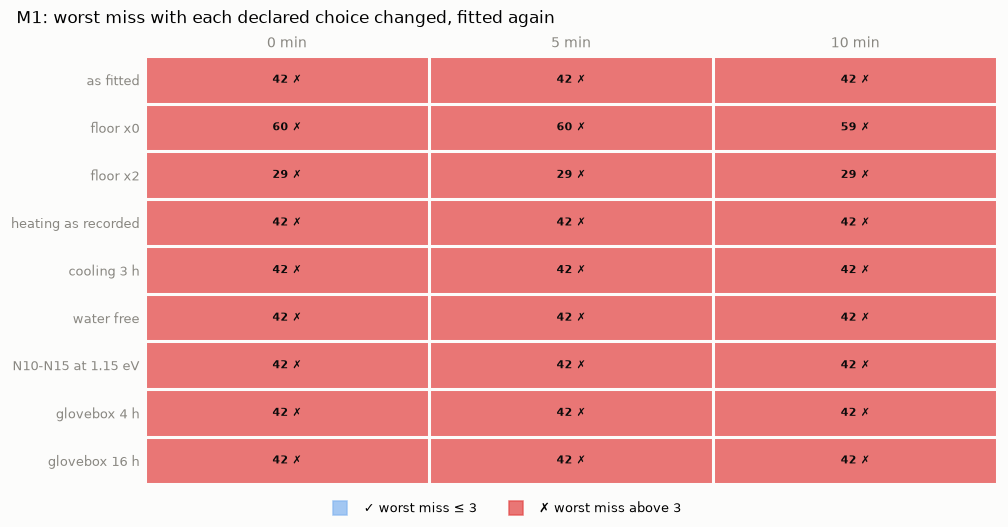

In [24]:
sensitivities = read_main('sensitivities')
# The run stored one variant under an earlier name: it is shown under the name the runner gives it now
renamed = [name for name in CONFIG['sensitivities'] if name not in SENSITIVITIES]
assert len(renamed) <= 1, renamed
sensitivities['variant'] = sensitivities['variant'].replace({name: 'N10-N15 at 1.15 eV' for name in renamed})
variants = list(dict.fromkeys(sensitivities['variant']))
fit_plots.plot_verdicts(by_age(sensitivities.pivot(index='variant', columns='scenario', values='max |z|')).reindex(variants),
                        title=f'{MAIN}: worst miss with each declared choice changed, fitted again');
variant_zero = sensitivities[sensitivities['scenario'] == '0 min'].set_index('variant')
(variant_zero[['chi2', 'max |z|', 'worst', *BARRIER_NAMES, 'c0 H2O TMSPa alone']]
 .rename(columns={**SHORT_NAMES, 'chi2': 'χ²', 'max |z|': 'worst miss', 'worst': 'where', 'c0 H2O TMSPa alone': 'water of TMSPa alone (M)'})
 .round(3).rename_axis('0 min'))

**What we see**

- **No variant fits under any reading.** In every variant but the two of the floor the worst miss stays 41.7 (`0.5 % H2O`, MMSPA).
- **The floor:** removed, χ² 7629 and worst miss 59.6 (a drift of `2 % H2O`), with hydrolysis moved furthest from its wall (1.24 eV); doubled, χ² 1090 and worst miss 28.8.
- **Heating as recorded** (17 min per step instead of 8 h) lowers χ² by 32 and moves only solvent attack (1.30 → 1.22 eV): with less time at 80 °C in `2 % H2O`, solvent attack can be faster for `TMSOH, glovebox` (4.2).
- **Water of `TMSPa alone` fitted:** 49 mM instead of the declared 65.6 mM; χ² 2499.
- **N10–N15 at 1.15 eV** makes it worse: χ² 2570, with hydrolysis at 0.875 eV.
- **Cooling before the spectra and the time in the glovebox** move χ² by less than 6.

--> No declared choice rescues M1. §8 collects what can be said.

## 8. What can be said, and what cannot

**Can be said: the same under the three readings**

| What | Value | Rests on |
|---|---|---|
| M1 does not fit | χ² 2520 for 80 values, worst miss 41.7 under every reading. No declared choice changes this (7.3), nor a trace of TMSOH at mixing (6.2) | all tubes |
| Where it fails | `0.5 % H2O` (75 % of χ²) and `2 % H2O` (22 %); by less, the first spectrum of `TMSPa alone` (6.8) and `TMSOH, glovebox` (5.0) | χ² tube by tube (4.1) |
| What it describes | `TMSPa + TMSOH (A)`, `TMSOH, probe` and the late spectrum of `TMSPa alone`, each within about 1.5 errors | §2.1 |
| Two separate reasons | (1) speed: one hydrolysis barrier cannot empty `2 % H2O` of TMSPA within minutes and leave `0.5 % H2O` almost untouched for 19 h. (2) Rest: the computed energies of R2, R3 and R4 put `2 % H2O` at another composition; the tube asks for each at 1.6σ to 2.3σ from its computed value, with the other sign | leave-one-out (4.2); `2 % H2O` by hand (5.1) |
| Without `2 % H2O` | χ² 57, worst miss 5.9, hydrolysis 1.37 eV: the other tubes come close to M1 | leave-one-out (4.2) |
| The method | on invented data made by M1 at 0 min the fit finds the barriers again: 8 of 8 true values inside their interval | recovery (7.1) |

**Cannot be said**

| Open point | Why | What would close it |
|---|---|---|
| The barriers | a model that does not fit has no confidence intervals; hydrolysis sits on the lowest value allowed (§5.2) | a model that fits |
| Whether the ages are near zero | M1 cannot tell: it empties the water tubes in milliseconds, so minutes do not matter to it; only transfer follows the reading | the mixing times |
| Which water tube says how fast hydrolysis is | `2 % H2O` asks for fast hydrolysis, `0.5 % H2O` for slow, and M1 has one barrier for both | the water of both tubes measured; a tube followed in time from mixing |

**Left out of this notebook on purpose**

- The other models of the run (M1+BEP, M5, M5-first and their '+BEP' forms): phase 2 was still running, and this notebook shows M1 alone.
- The predictions of the run for M1 (tube B, the later ¹³C of tube A, storage at 25 °C, the bench protocol): they rest on a fit, and M1 does not fit.